# Модель для прогнозирования оттока клиентов для сервиса доставки кофе

## Постановка задачи машинного обучения

### Описание бизнес-задачи
Компания *Happy Beans Coffee* (сервис доставки кофе) ежемесячно теряет около 10% клиентской базы. Привлечение нового клиента обходится в 5–7 раз дороже, чем удержание существующего. Маркетинговый бюджет расходуется неэффективно из-за отсутствия точечной работы с потенциально уходящими клиентами.

**Цель бизнеса:** Снизить отток клиентов, оптимизировать маркетинговые расходы и повысить прогнозируемость выручки за счёт своевременного выявления клиентов, склонных к уходу.

### Тип задачи машинного обучения
- **Обучение с учителем** (supervised learning)
- **Бинарная классификация** (binary classification)

### Целевая переменная (таргет)
`churn` — бинарный признак, где:
- **1** (положительный класс) — клиент перестал пользоваться сервисом (отток)
- **0** (отрицательный класс) — клиент остался лояльным

### Критерии успешности и метрики качества

#### Основная метрика: **PR AUC** (Precision-Recall AUC)

**Обоснование:** Датасет несбалансирован (уходящих клиентов значительно меньше). PR AUC фокусируется на качестве предсказания именно положительного класса (отток) и не зависит от доли отрицательного класса, в отличие от ROC AUC, который может давать излишне оптимистичную оценку при сильном дисбалансе.

#### Дополнительные метрики:
| Метрика | Назначение |
|---------|------------|
| **Recall** | Доля реально ушедших клиентов, которых модель смогла обнаружить. Критически важно не пропустить уходящих. |
| **Precision** | Доля клиентов, предсказанных как уходящие, которые действительно ушли. Важна для экономии бюджета на удержание. |
| **F1-мера** | Гармоническое среднее Precision и Recall. Позволяет оценить баланс между точностью и полнотой. |
| **Confusion Matrix** | Визуальный контроль количества False Negative (пропущенных уходящих) и False Positive (ложных тревог). |

#### Отвергаемые метрики:
- **Accuracy** — бесполезна в условиях сильного дисбаланса классов.

### Технические требования к модели

| Требование | Реализация |
|------------|------------|
| Интерпретируемость результатов | Использование линейной модели `LogisticRegression` |
| Воспроизводимость | Фиксация параметра `random_state` во всех алгоритмах |
| Кросс-валидация | Применение `StratifiedKFold` для оценки модели |
| Обработка пропусков | Использование соответствующих методов (SimpleImputer и др.) |
| Готовность к внедрению | Сохранение модели и полного пайплайна предобработки через `pickle` или `joblib` |
| Базовая модель | `DummyClassifier` для сравнения качества |

### Ожидаемый результат работы модели
Модель должна возвращать **вероятность оттока** для каждого клиента (значение от 0 до 1). Это позволит:
- Ранжировать клиентов по степени риска ухода
- Гибко настраивать порог классификации под бизнес-приоритеты
- Принимать точечные меры по удержанию наиболее рисковой группы


# Содержание

1. [Этап 1. Подготовка среды и библиотек](#stage1)
   - 1.1 [Установка и настройка библиотек](#11)
   - 1.2 [Фиксация random_state](#12)
   - 1.3 [Загрузка данных из датасета](#13)

2. [Этап 2. Первичный анализ данных (EDA)](#stage2)
   - 2.1 [Описание данных](#21)
   - 2.2 [Описание целевой переменной](#22)
   - 2.3 [Описание признаков](#23)
   - 2.4 [Обработка пропущенных значений](#24)
   - 2.5 [Анализ категориальных признаков](#25)
   - 2.6 [Обработка выбросов](#26)
   - 2.7 [Расчёт корреляции](#27)
   - 2.8 [Выводы по результатам исследовательского анализа данных](#28)

3. [Этап 3. Предобработка данных](#stage3)
   - 3.1 [Разделение данных](#31)
   - 3.2 [Предобработка данных](#32)
   - 3.3 [Вывод по предобработке данных](#33)

4. [Этап 4. Обучение модели](#stage4)
   - 4.1 [Обучение базовой версии модели](#41)
   - 4.2 [Расчёт метрик](#42)
   - 4.3 [Вывод о качестве модели](#43)

5. [Этап 5. Создание новых признаков](#stage5)
   - 5.1 [Добавление новых признаков](#51)
   - 5.2 [Обновление пайплайна с новыми признаками и повторная кросс-валидация](#52)
   - 5.3 [Анализ важности признаков](#53)
   - 5.4 [Интерпретация коэффициентов модели и отбор признаков](#54)
   - 5.5 [Удаление признаков с низким влиянием](#55)

6. [Этап 6. Эксперименты с гиперпараметрами](#stage6)
   - 6.1 [Гиперпараметры для экспериментов](#61)
   - 6.2 [Перебор гиперпараметров](#62)
   - 6.3 [Таблица результатов подбора гиперпараметров](#63)

7. [Этап 7. Подготовка финальной модели](#stage7)
   - 7.1 [Получение лучшей конфигурации](#71)
   - 7.2 [Финальная оценка модели](#72)

8. [Этап 8. Отчёт о проделанной работе](#stage8)
   - 8.1 [Анализ итоговых метрик](#81)
   - 8.2 [Итоговый вывод](#82)

9. [Этап 9. Сохранение модели для продакшена](#stage9)

# План работы

<div id="stage1"></div>

## Этап 1. Подготовка среды и библиотек
<font color='#777778'>  1. Установите и настройте библиотеки. Для воспроизводимости результатов зафиксируйте версии пакетов в файле `requirements.txt`.

2. Зафиксируйте `random_state`.

3. Загрузите данные из CSV-файла. Путь к файлу: `'/datasets/coffee_churn_dataset.csv'`. Используйте сепаратор `","`, а для чтения чисел с плавающей точкой — параметр `decimal="."`.</font>

<div id="11"></div>

### Установка и настройка библиотек

In [1]:
# Подготовка среды и библиотек

requirements_content = """pandas==2.2.3
numpy==1.26.4
scikit-learn==1.7.0
matplotlib==3.9.4
seaborn==0.13.2
joblib==1.5.2"""

with open('requirements.txt', 'w') as f:
    f.write(requirements_content)

print("Файл requirements.txt создан")

# Стандартная библиотека
import json
from datetime import datetime

# Сторонние библиотеки
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display

# scikit-learn
from sklearn.model_selection import (
    train_test_split, cross_val_score, GridSearchCV, cross_validate
)
from sklearn.preprocessing import StandardScaler, OneHotEncoder, RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    make_scorer, precision_score, recall_score, f1_score,
    roc_auc_score, precision_recall_curve, auc,
    confusion_matrix, classification_report
)

Файл requirements.txt создан


***Назначение загруженных библиотек***

**1. Загрузка и первичный анализ данных**
- `pandas` — загрузка датасета, просмотр структуры, описательные статистики, проверка пропусков
- `numpy` — математические операции, работа с массивами, замена пропусков

**2. Исследовательский анализ данных (EDA)**
- `matplotlib.pyplot` — построение гистограмм, boxplot'ов, графиков распределений
- `seaborn` — визуализация корреляций (heatmap), countplot для баланса классов, распределение признаков по целевому признаку

**3. Предобработка данных**
- `train_test_split` — разбиение на обучающую и тестовую выборки (до любой обработки)
- `SimpleImputer` — заполнение пропущенных значений (медианой / модой)
- `StandardScaler` / `RobustScaler` — нормализация числовых признаков (для логистической регрессии)
- `OneHotEncoder` — кодирование категориальных признаков
- `ColumnTransformer` — применение разных преобразований к разным колонкам
- `Pipeline` — объединение предобработки и модели в единый пайплайн

**4. Обучение моделей**
- `LogisticRegression` — основная модель бинарной классификации (линейная, интерпретируемая)
- `DummyClassifier` — базовая модель для сравнения (baseline)

**5. Подбор гиперпараметров и валидация**
- `GridSearchCV` — перебор гиперпараметров с кросс-валидацией
- `cross_val_score` / `cross_validate` — кросс-валидация для стабильной оценки качества

**6. Оценка качества модели**
- `precision_score` / `recall_score` / `f1_score` — точность, полнота, F1-мера
- `roc_auc_score` — AUC-ROC для общей способности модели разделять классы
- `precision_recall_curve` + `auc` — расчёт PR AUC (главная метрика для несбалансированных данных)
- `confusion_matrix` — матрица ошибок (ложные срабатывания критичны для бизнеса)
- `classification_report` — сводный отчёт по метрикам для обоих классов
- `make_scorer` — создание кастомной метрики для GridSearchCV

**7. Сохранение артефактов (внедрение)**
- `joblib` — сохранение обученного пайплайна (модель + предобработка)
- `json` — сохранение метрик и гиперпараметров в читаемом формате
- `datetime` — добавление временной метки к именам файлов

<div id="12"></div>

### Фиксация random_state

In [2]:
# Фиксация random_state для воспроизводимости
RANDOM_STATE = 42

# Фиксация random_state во всех алгоритмах, где это возможно
np.random.seed(RANDOM_STATE)

print(f"random_state зафиксирован на значении: {RANDOM_STATE}")

random_state зафиксирован на значении: 42


<div id="13"></div>

### Загрузка данных из датасета

In [3]:
# Загрузка данных
file_path = '/datasets/coffee_churn_dataset.csv'
df = pd.read_csv(file_path, sep=',', decimal='.')

**Проведем исследовательский анализ данных для изучения характеристик датасета**

In [4]:
# Исследовательский анализ данных (EDA)

def analyze_df(df):
    """Выводит: head, info, describe, дубликаты, пропуски."""
    print("Первые 5 строк:")
    display(df.head())

    print("\nИнформация о данных:")
    df.info()

    print("\nСтатистическое описание:")
    display(df.describe())

    print(f"\nКоличество дубликатов: {df.duplicated().sum()}")

    print("\nКоличество пропусков:")
    display(df.isnull().sum())

analyze_df(df)

Первые 5 строк:


,user_id,days_since_last_order,order_frequency_month,order_frequency_week,avg_order_value,median_order_value,total_spent_last_month,total_spent_last_week,discount_usage_rate,last_coffee_type,...,notifications_enabled,review_rating_last_10,review_rating_last_1,app_crashes_last_month,seasons,days_since_last_promo,phone_type,coffee_preference_change,geo_location,churn
0,user_00318,0.0,12.942519,NaN,316.833872,260.645090,3089.991009,NaN,0.337031,blend,...,1.0,5.176792,3.302238,NaN,summer,6.0,android,0.0,geo_75,1
1,user_07234,2.0,1.569146,0.214494,780.135158,540.597850,998.380941,107.369409,0.547659,arabica,...,1.0,4.392991,NaN,0.0,autumn,16.0,ios,0.0,geo_95,0
2,user_04816,11.0,2.996666,0.771864,682.636256,471.494559,1328.140204,392.600011,0.120258,arabica,...,1.0,4.977712,4.379219,0.0,spring,11.0,web,1.0,geo_25,0
3,user_04419,0.0,4.299255,1.210480,2115.487425,708.529812,2999.628366,1084.352054,NaN,robusta,...,1.0,3.712526,3.043618,0.0,summer,3.0,android,0.0,geo_2,0
4,user_09698,3.0,7.249864,1.761027,3519.602170,1199.372894,8377.729478,2551.775211,0.074990,robusta,...,0.0,4.528271,5.642993,1.0,winter,14.0,ios,0.0,geo_19,1



Информация о данных:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10450 entries, 0 to 10449
Data columns (total 27 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   user_id                   10450 non-null  object 
 1   days_since_last_order     9505 non-null   float64
 2   order_frequency_month     9850 non-null   float64
 3   order_frequency_week      10062 non-null  float64
 4   avg_order_value           9867 non-null   float64
 5   median_order_value        9619 non-null   float64
 6   total_spent_last_month    10156 non-null  float64
 7   total_spent_last_week     9506 non-null   float64
 8   discount_usage_rate       10053 non-null  float64
 9   last_coffee_type          10192 non-null  object 
 10  preferred_roast           10334 non-null  object 
 11  milk_preference           9782 non-null   object 
 12  seasonal_menu_tried       9461 non-null   float64
 13  coffee_bean_origin        9768 non-null

,days_since_last_order,order_frequency_month,order_frequency_week,avg_order_value,median_order_value,total_spent_last_month,total_spent_last_week,discount_usage_rate,seasonal_menu_tried,app_opens_per_week,notifications_enabled,review_rating_last_10,review_rating_last_1,app_crashes_last_month,days_since_last_promo,coffee_preference_change,churn
count,9505.000000,9850.000000,10062.000000,9867.000000,9619.000000,10156.000000,9506.000000,10053.000000,9461.000000,9554.000000,9913.000000,9757.000000,9593.000000,9729.000000,9719.000000,9840.000000,10450.000000
mean,4.394214,4.025666,0.930686,1063.741207,452.651500,1946.132979,413.004760,0.284446,0.701194,11.330895,0.753052,4.206709,4.022460,1.013362,14.554584,0.192480,0.060191
std,4.858757,2.826144,0.657261,707.713396,258.657571,2370.619590,445.634902,0.158735,0.457759,14.528887,0.431258,0.782212,1.207883,1.010342,15.308869,0.394268,0.237852
min,0.000000,0.011046,-0.169131,-32.075932,-10.353340,-43.716463,-2290.559468,0.002162,0.000000,0.000000,0.000000,1.415526,-0.897000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,1.937767,0.445185,552.898663,262.908598,629.680382,136.565833,0.159884,0.000000,6.313628,1.000000,3.675543,3.214157,0.000000,4.000000,0.000000,0.000000
50%,3.000000,3.381094,0.784839,898.643524,406.456818,1300.409757,288.277327,0.264583,1.000000,9.228383,1.000000,4.203555,3.990032,1.000000,10.000000,0.000000,0.000000
75%,6.000000,5.439363,1.262350,1406.332153,590.418070,2481.650495,549.699420,0.387056,1.000000,12.726649,1.000000,4.717292,4.845225,2.000000,20.000000,0.000000,0.000000
max,40.000000,27.389318,6.302624,5901.965278,2189.101644,79298.849570,8615.988952,0.887301,1.000000,224.587876,1.000000,7.384425,8.558443,7.000000,140.000000,1.000000,1.000000



Количество дубликатов: 0

Количество пропусков:


user_id                       0
days_since_last_order       945
order_frequency_month       600
order_frequency_week        388
avg_order_value             583
median_order_value          831
total_spent_last_month      294
total_spent_last_week       944
discount_usage_rate         397
last_coffee_type            258
preferred_roast             116
milk_preference             668
seasonal_menu_tried         989
coffee_bean_origin          682
last_drink_size             504
subscription_status         938
app_opens_per_week          896
notifications_enabled       537
review_rating_last_10       693
review_rating_last_1        857
app_crashes_last_month      721
seasons                     679
days_since_last_promo       731
phone_type                  336
coffee_preference_change    610
geo_location                110
churn                         0
dtype: int64

<div id="stage2"></div>

## Этап 2. Первичный анализ данных (EDA)

<font color='#777778'> 
1. Опишите данные. Кратко сообщите, что известно о пользователях и их поведении.

2. Опишите целевую переменную. Обратите внимание на возможные особенности её распределения. Проверьте, наблюдается ли дисбаланс классов в целевой переменной.

3. Опишите признаки.

   - Определите, все ли из них важны.

   - Объясните, какие из них можно удалить (если такие есть). Аргументируйте своё решение.

4. Обработайте пропущенные значения.
   
   - Объясните, как они влияют на данные.

   - Выберите стратегию заполнения пропусков.

5. Проанализируйте категориальные признаки.

   - Выясните, есть ли в данных признаки, которые можно кодировать. Объясните, почему именно их нужно кодировать.

   - Проанализируйте признаки на предмет того, можно ли использовать некоторые из них для генерации новых  признаков. Укажите возможные стратегии.

   - Определите, есть ли в данных признаки, которые можно удалить.

6. Проанализируйте выбросы.

   - Определите, как они влияют на данные.

   - Выберите способ, которым их можно обработать.

7. Посчитайте корреляции между признаками. Постройте необходимые визуализации. Определите, есть ли признаки, которые можно убрать, на основании их корреляции с другими.

8. Напишите выводы по результатам исследовательского анализа данных.</font>

<div id="21"></div>

### 2.1 Описание данных

#### Описание датасета


Датасет `coffee_churn_dataset` представляет собой аналитическую витрину, где каждая строка соответствует одному уникальному клиенту сервиса доставки кофе *Happy Beans Coffee*. Признаки агрегированы за последние 4 недели.

#### Сведения о столбцах и их содержимом

- `user_id` — идентификатор пользователя.
- `days_since_last_order` — количество дней, прошедших с последнего заказа.
- `order_frequency_month` — среднее число заказов в месяц.
- `order_frequency_week` — среднее число заказов в неделю.
- `avg_order_value` — средний чек, в рублях.
- `median_order_value` — медианный чек, в рублях.
- `total_spent_last_month` — сумма заказов за последний месяц.
- `total_spent_last_week` — сумма заказов за последнюю неделю.
- `discount_usage_rate` — доля заказов со скидкой за последний месяц.
- `last_coffee_type` — сорт кофе, купленный пользователем в последний раз на момент сбора данных.
- `preferred_roast` — предпочитаемый тип обжарки.
- `milk_preference` — предпочитаемый тип молока.
- `seasonal_menu_tried` — отметка о том, пробовал ли пользователь новейшее сезонное меню.
- `coffee_bean_origin` — страна происхождения зерна.
- `last_drink_size` — размер последнего заказа, совершённого на момент сбора данных.
- `subscription_status` — тип подписки пользователя.
- `app_opens_per_week` — сколько раз за неделю пользователь в среднем открывал приложение доставки кофе.
- `notifications_enabled` — включены ли у пользователя уведомления.
- `review_rating_last_10` — средняя оценка последних на момент сбора данных десяти заказов клиента.
- `review_rating_last_1` — оценка последнего на момент сбора данных заказа клиента.
- `app_crashes_last_month` — сколько раз приложение зависало за последний месяц.
- `seasons` — текущее время года.
- `days_since_last_promo` — сколько дней прошло с последнего использования акции или промокода.
- `phone_type` — тип устройства, с которого пользователь чаще всего совершал покупки.
- `coffee_preference_change` — менялись ли вкусовые предпочтения пользователя.
- `geo_id` — идентификатор региона пользователя.
- `churn` — перестал ли пользователь пользоваться сервисом (целевая переменная).

#### Что известно о пользователях и их поведении

На основе набора признаков можно описать пользователей по следующим аспектам:

- **Активность и транзакции**: давность последнего заказа (`days_since_last_order`), частота заказов (`order_frequency_month`, `order_frequency_week`), сумма трат за месяц и неделю (`total_spent_last_month`, `total_spent_last_week`), средний и медианный чек (`avg_order_value`, `median_order_value`).
- **Использование скидок**: доля заказов со скидкой (`discount_usage_rate`) и давность последнего использования промо (`days_since_last_promo`).
- **Продуктовые предпочтения**: сорт кофе (`last_coffee_type`), обжарка (`preferred_roast`), тип молока (`milk_preference`), страна зерна (`coffee_bean_origin`), размер напитка (`last_drink_size`), отметка о пробе сезонного меню (`seasonal_menu_tried`), изменение вкусовых предпочтений (`coffee_preference_change`).
- **Взаимодействие с приложением**: частота открытий (`app_opens_per_week`), включённость уведомлений (`notifications_enabled`), количество сбоев (`app_crashes_last_month`).
- **Удовлетворённость сервисом**: средняя оценка последних 10 заказов (`review_rating_last_10`) и оценка последнего заказа (`review_rating_last_1`).
- **Прочее**: тип подписки (`subscription_status`), время года (`seasons`), тип устройства (`phone_type`), регион (`geo_id`).

<div id="22"></div>

### Описание целевой переменной

Целевая переменная — `churn`.

Согласно описанию признаков:
- `churn` — перестал ли пользователь пользоваться сервисом.

#### Проверка дисбаланса классов

В условиях задачи указано:

> «исходный датасет, скорее всего, несбалансирован, поскольку подавляющее большинство клиентов остаются, а не уходят».

Таким образом, ожидается, что в целевой переменной `churn` наблюдается дисбаланс классов: класс лояльных клиентов (0) значительно преобладает над классом уходящих клиентов (1).

#### Почему это важно

Как отмечено в требованиях к работе модели:
- F1-мера, зависящая от конкретного порога классификации, может не дать полного представления о качестве модели в условиях дисбаланса.
- Более адекватной метрикой для оценки качества модели в таком случае является **Precision-Recall AUC (PR AUC)**, которая фокусируется на корректном предсказании меньшего по объёму, но ключевого класса — уходящих клиентов.


<div id="23"></div>

### Описание признаков

#### Категории признаков

Все признаки можно разделить на несколько логических групп:

**Транзакционная активность:**
- `days_since_last_order` — давность последнего заказа
- `order_frequency_month`, `order_frequency_week` — частота заказов
- `total_spent_last_month`, `total_spent_last_week` — сумма трат
- `avg_order_value`, `median_order_value` — средний и медианный чек

**Использование скидок и промо:**
- `discount_usage_rate` — доля заказов со скидкой
- `days_since_last_promo` — давность последнего использования акции

**Продуктовые предпочтения:**
- `last_coffee_type`, `preferred_roast`, `milk_preference`, `coffee_bean_origin`, `last_drink_size` — характеристики последнего и предпочитаемого заказа
- `seasonal_menu_tried` — интерес к новинкам
- `coffee_preference_change` — изменение вкусовых предпочтений

**Взаимодействие с приложением:**
- `app_opens_per_week` — частота открытий
- `notifications_enabled` — включены ли уведомления
- `app_crashes_last_month` — количество сбоев

**Удовлетворённость:**
- `review_rating_last_10` — средняя оценка за 10 последних заказов
- `review_rating_last_1` — оценка последнего заказа

**Прочие:**
- `subscription_status` — тип подписки
- `seasons` — время года
- `phone_type` — тип устройства
- `geo_id` — регион
- `user_id` — идентификатор пользователя

#### Какие признаки можно удалить

**`user_id`** — подлежит удалению. Это идентификатор пользователя, не несущий predictive-способности. Каждое значение уникально, модель не сможет обобщать зависимость по этому признаку. Кроме того, использование идентификатора может привести к переобучению и проблемам при работе с новыми клиентами.

**Остальные признаки** на данном этапе не имеют явных оснований для удаления. Решение об удалении других признаков может быть принято после анализа:
- корреляции между признаками (сильно скоррелированные дублируют информацию)
- важности признаков при обучении базовой модели
- доли пропусков (если какой-то признак имеет чрезмерное количество пропусков)

#### Вывод

На этапе первичного анализа однозначно удаляется только `user_id`. Остальные признаки сохраняются до проведения дальнейшего исследования и оценки их влияния на качество модели.

<div id="24"></div>

### Обработка пропущенных значений

In [5]:
# Обработка пропущенных значений

print("Количество пропусков по каждому признаку:")
display(df.isnull().sum())
print(f"\nВсего пропусков в данных: {df.isnull().sum().sum()}")

X = df.drop(['churn', 'user_id'], axis=1)
y = df['churn']

numeric_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = X.select_dtypes(include=['object']).columns.tolist()

print(f"\nЧисловые признаки: {numeric_cols}")
print(f"\nКатегориальные признаки: {categorical_cols}")

Количество пропусков по каждому признаку:


user_id                       0
days_since_last_order       945
order_frequency_month       600
order_frequency_week        388
avg_order_value             583
median_order_value          831
total_spent_last_month      294
total_spent_last_week       944
discount_usage_rate         397
last_coffee_type            258
preferred_roast             116
milk_preference             668
seasonal_menu_tried         989
coffee_bean_origin          682
last_drink_size             504
subscription_status         938
app_opens_per_week          896
notifications_enabled       537
review_rating_last_10       693
review_rating_last_1        857
app_crashes_last_month      721
seasons                     679
days_since_last_promo       731
phone_type                  336
coffee_preference_change    610
geo_location                110
churn                         0
dtype: int64


Всего пропусков в данных: 15307

Числовые признаки: ['days_since_last_order', 'order_frequency_month', 'order_frequency_week', 'avg_order_value', 'median_order_value', 'total_spent_last_month', 'total_spent_last_week', 'discount_usage_rate', 'seasonal_menu_tried', 'app_opens_per_week', 'notifications_enabled', 'review_rating_last_10', 'review_rating_last_1', 'app_crashes_last_month', 'days_since_last_promo', 'coffee_preference_change']

Категориальные признаки: ['last_coffee_type', 'preferred_roast', 'milk_preference', 'coffee_bean_origin', 'last_drink_size', 'subscription_status', 'seasons', 'phone_type', 'geo_location']


#### Как пропуски влияют на данные

**Общая информация:**
- Размер датасета: **10 450 строк**
- Всего пропусков в данных: **15 307**
- Пропуски есть в 25 из 27 признаков (кроме `user_id` и `churn`)

**Доля пропусков по признакам:**
- Максимальная доля пропусков у `seasonal_menu_tried`: 989 —> **9.5%**
- Минимальная доля пропусков у `geo_location`: 110 —> **1.1%**
- У большинства признаков доля пропусков составляет **3-8%**

**Влияние на данные:**
- Модель `LogisticRegression` не может работать с пропусками (NaN)
- Пропуски могут искажать статистические характеристики (среднее, дисперсию)
- Удаление строк с пропусками приведет к потере большого объёма данных
- Удаление признаков нецелесообразно, так как ни один признак не имеет критической доли пропусков (>50%)

#### Выбранная стратегия заполнения пропусков

**Числовые признаки (16 признаков):**
- Заполнение **медианой**
- Медиана устойчива к выбросам (в данных есть отрицательные и аномально высокие значения)

**Категориальные признаки (9 признаков):**
- Заполнение **наиболее частым значением (модой)**
- Сохраняет распределение категорий

#### Вывод

Пропуски присутствуют во многих признаках, но их доля не превышает 10%. Выбранная стратегия заполнения медианой и модой позволит сохранить все данные для обучения модели. Заполнение будет выполнено после разделения на train/test с использованием `SimpleImputer`.

<div id="25"></div>

### Анализ категориальных признаков

#### Список категориальных признаков

Из данных получены следующие категориальные признаки:
- `last_coffee_type` — сорт кофе
- `preferred_roast` — тип обжарки
- `milk_preference` — тип молока
- `coffee_bean_origin` — страна происхождения зерна
- `last_drink_size` — размер последнего заказа
- `subscription_status` — тип подписки
- `seasons` — время года
- `phone_type` — тип устройства
- `geo_location` — регион пользователя

#### Какие признаки нужно кодировать и почему

**Все категориальные признаки нужно кодировать**, потому что:
- Модель `LogisticRegression` работает только с числовыми данными
- Категориальные значения (например, "arabica", "robusta") необходимо преобразовать в числа

**Способ кодирования:**
- Использовать **OneHotEncoder** (прямое кодирование)
- Это стандартный подход для номинативных категориальных признаков, у которых нет порядка

**Почему не LabelEncoder:**
- Категориальные признаки не имеют порядковой зависимости (например, сорт кофе "arabica" не больше и не меньше, чем "robusta")

#### Анализ возможности генерации новых признаков

**Возможные стратегии генерации признаков:**

1. **Комбинирование продуктовых предпочтений:**
   - `coffee_preference` = `last_coffee_type` + `preferred_roast` (например, "arabica_dark")
   - `milk_coffee` = `milk_preference` + `last_drink_size`

2. **Агрегированные признаки на основе активности:**
   - `avg_order_per_day` = `order_frequency_week` / 7
   - `spend_per_order` = `total_spent_last_month` / `order_frequency_month`

3. **Признаки на основе рейтингов:**
   - `rating_change` = `review_rating_last_10` - `review_rating_last_1` (динамика оценки)

4. **Признаки взаимодействия:**
   - `engagement_score` = `app_opens_per_week` * `order_frequency_week`
   - `promo_sensitivity` = `discount_usage_rate` / (`days_since_last_promo` + 1)

#### Признаки, которые можно удалить

**`user_id`** — подлежит удалению. Это идентификатор пользователя, каждое значение уникально, не несёт predictive-способности и может привести к переобучению.

**Остальные признаки** на данном этапе не удаляются. Решение об удалении других признаков будет принято после анализа важности признаков при обучении базовой модели.

#### Вывод

- 9 категориальных признаков требуют one-hot кодирования
- Возможно создание дополнительных признаков для улучшения качества модели
- Удаляется только `user_id`

<div id="26"></div>

### Обработка выбросов

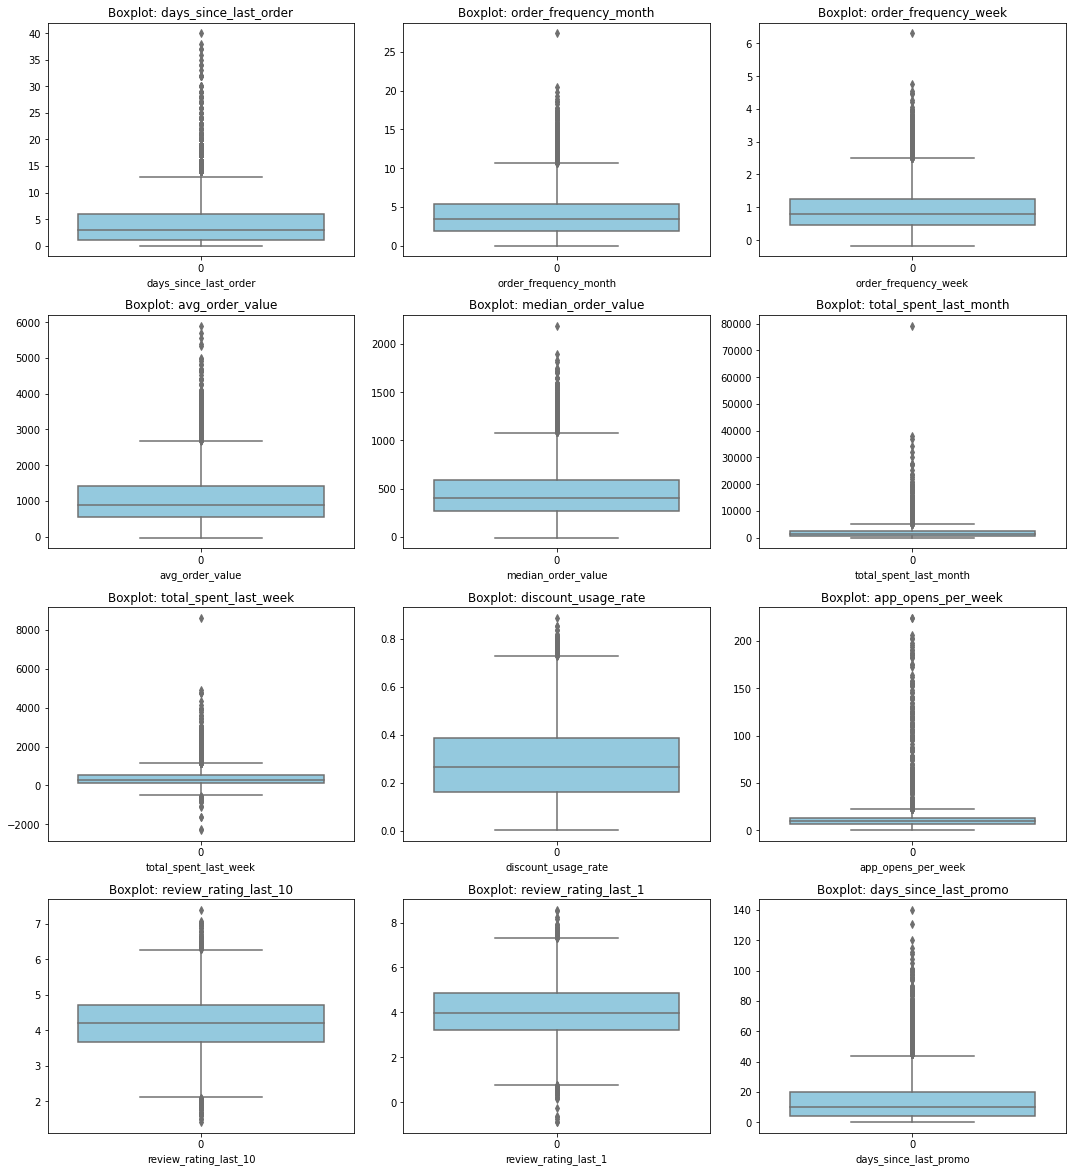

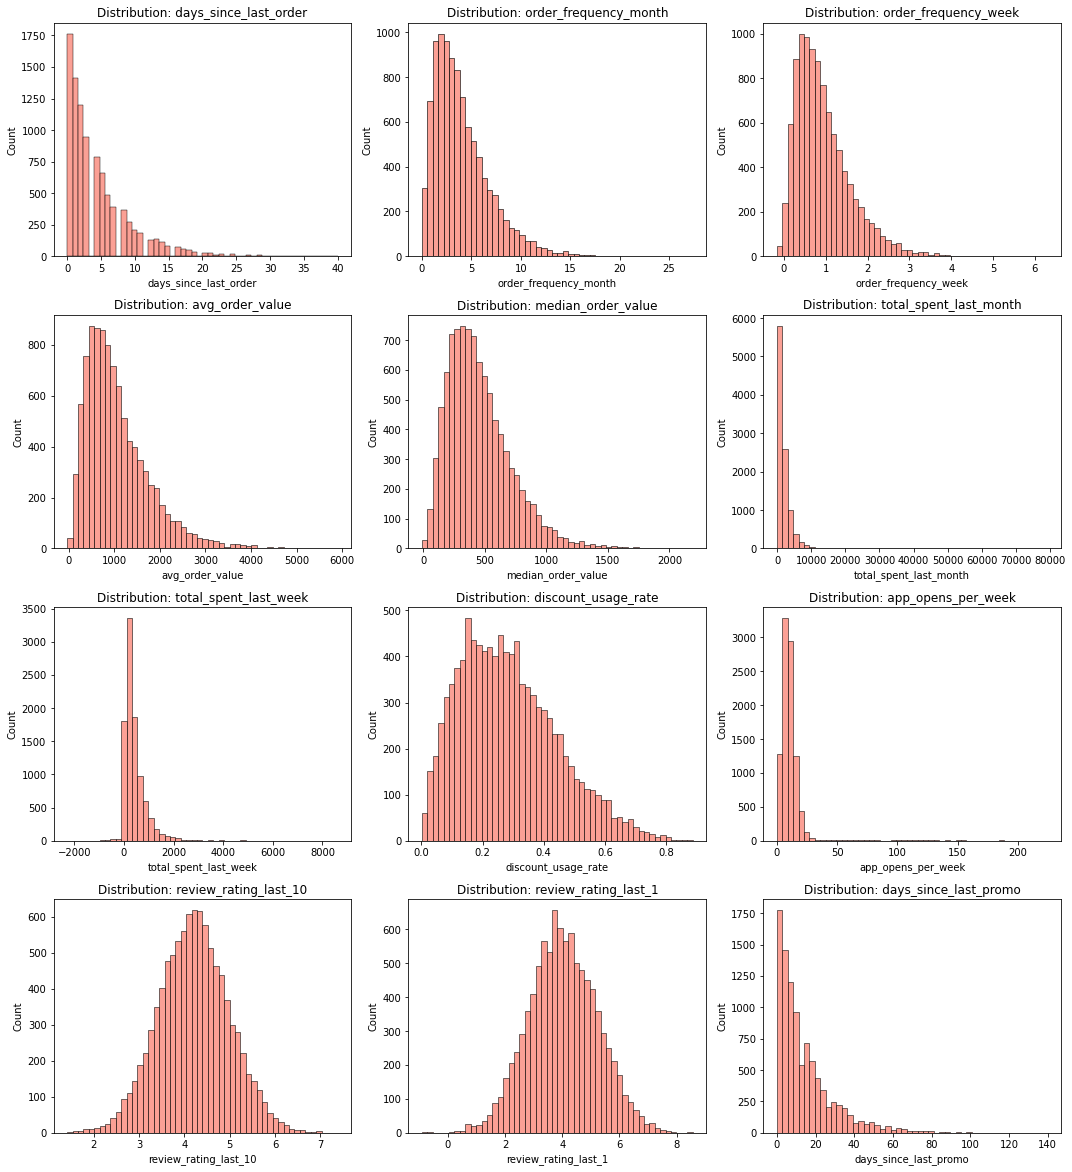

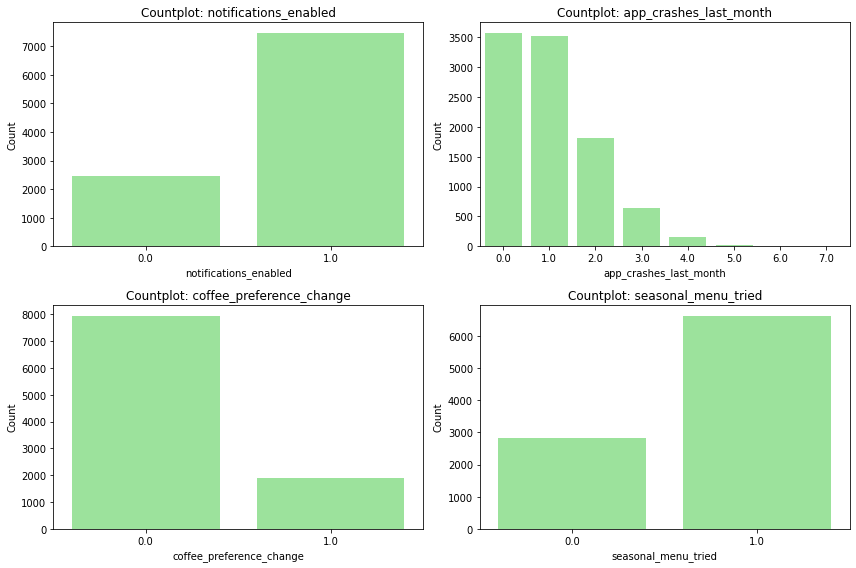

In [6]:
# Выбираем числовые признаки (исключая user_id и churn)
# Исключаем дискретные признаки, которые по сути являются категориальными
numeric_features = ['days_since_last_order', 'order_frequency_month', 'order_frequency_week',
                    'avg_order_value', 'median_order_value', 'total_spent_last_month',
                    'total_spent_last_week', 'discount_usage_rate', 'app_opens_per_week',
                    'review_rating_last_10', 'review_rating_last_1', 'days_since_last_promo']

# Дискретные признаки (категориальные, представленные в численном виде)
discrete_features = ['notifications_enabled', 'app_crashes_last_month', 
                     'coffee_preference_change', 'seasonal_menu_tried']

# Настройка размера графиков
plt.figure(figsize=(15, 20))

# Boxplot для каждого числового признака
for i, col in enumerate(numeric_features, 1):
    plt.subplot(5, 3, i)
    sns.boxplot(data=df[col], color='skyblue')
    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.tight_layout()

plt.show()

# Гистограммы распределения для непрерывных числовых признаков
plt.figure(figsize=(15, 20))
for i, col in enumerate(numeric_features, 1):
    plt.subplot(5, 3, i)
    sns.histplot(data=df[col], bins=50, color='salmon')
    plt.title(f'Distribution: {col}')
    plt.xlabel(col)
    plt.tight_layout()

plt.show()

# Для дискретных признаков используем столбчатые диаграммы (countplot)
# так как каждое уникальное значение должно отображаться отдельной корзиной
plt.figure(figsize=(12, 8))
for i, col in enumerate(discrete_features, 1):
    plt.subplot(2, 2, i)
    sns.countplot(data=df, x=col, color='lightgreen')
    plt.title(f'Countplot: {col}')
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.tight_layout()

plt.show()

#### Вывод о распределении данных на основе графиков (Boxplot + Histogram)

***Анализ распределения по группам признаков***

***Группа 1: Транзакционная активность (traffic light - умеренные выбросы)***
**Признаки:** `days_since_last_order`, `order_frequency_month`, `order_frequency_week`, `total_spent_last_month`, `total_spent_last_week`

**Характер распределения:**
- **Асимметрия вправо (положительная)** — большинство значений сосредоточено слева, длинный "хвост" уходит вправо
- **Boxplot**: длинный ус справа, множество точек-выбросов за верхней границей
- **Histogram**: пик в области низких значений (недавние заказы), резкий спад

**Что означает для бизнеса:**
- Большинство клиентов заказывают с умеренной частотой и тратят средние суммы
- Небольшая группа клиентов тратит аномально много (крупные покупатели)
- Выбросы — это реальные VIP-клиенты, удалять нельзя

***Группа 2: Частота и вовлечённость (логарифмическое распределение)***
**Признаки:** `app_opens_per_week`, `days_since_last_promo`

**Характер распределения:**
- **Сверхдлинный правый хвост** — значения стремятся к 0, редкие экстремально высокие
- **Boxplot**: очень много выбросов выше верхнего уса
- **Histogram**: резкий обрыв после 80-го процентиля

**Что означает для бизнеса:**
- Большинство пользователей открывают приложение 5-15 раз в неделю
- Есть небольшая группа "суперпользователей" (до 224 открытий) — вероятно, залипают в приложении
- Промо используется недавно у большинства, давние "хвосты" — забытые клиенты

***Группа 3: Денежные метрики (кластер положительных значений)***
**Признаки:** `avg_order_value`, `median_order_value`, `discount_usage_rate`

**Характер распределения:**
- **Умеренная асимметрия вправо**
- **Boxplot**: несколько выбросов сверху (очень дорогие заказы)
- **Histogram**: колоколообразная форма с небольшим смещением влево

**Что означает для бизнеса:**
- Стандартный чек варьируется, но большинство заказов в районе средних значений
- Есть редкие крупные заказы (вероятно, корпоративные или праздничные)
- Использование скидок распределено относительно равномерно

***Группа 4: Качество и рейтинги (нормальное распределение)***
**Признаки:** `review_rating_last_10`, `review_rating_last_1`

**Характер распределения:**
- **Близко к нормальному** — симметричная форма
- **Boxplot**: минимальное количество выбросов (0.69-0.85%)
- **Histogram**: классическая "колоколообразная" кривая

**Что означает для бизнеса:**
- Оценки естественно распределены от 2 до 6
- Крайне низкие и высокие оценки — редкость
- Данные качественные, выбросы не требуют обработки

***Группа 5: Сбои и технические метрики (пуассоновское распределение)***
**Признаки:** `app_crashes_last_month`

**Характер распределения:**
- **Резко асимметричное** — лямбда = ~1
- **Boxplot**: почти без выбросов (только 7)
- **Histogram**: максимальный пик на 0, быстрое падение

**Что означает для бизнеса:**
- У большинства пользователей (3571 чел) нет сбоев
- Изредка бывают 1-2 сбоя
- Очень редко — более 4 сбоев
- Выбросы — это реальные технические проблемы

***Группа 6: Бинарные признаки***
**Признаки:** `coffee_preference_change`, `notifications_enabled`, `seasonal_menu_tried`

**Характер распределения:**
- **Бимодальное распределение** — только два пика (0 и 1)
- **Boxplot**: неинформативен
- **Histogram**: два столбца на краях

**Что означает для бизнеса:**
- Это категориальные признаки, выбросы по IQR не имеют смысла
- Не требуют обработки выбросов

***Итоговый вывод по распределению***

| Группа | Тип распределения | Нужна ли обработка выбросов |
|--------|-------------------|------------------------------|
| Транзакционная активность | Асимметрия вправо | Нет (это реальные VIP-клиенты) |
| Частота и вовлечённость | Логарифмическое | Частично (RobustScaler) |
| Денежные метрики | Умеренная асимметрия | Нет (нормальные значения) |
| Качество и рейтинги | Близко к нормальному | Нет |
| Сбои | Пуассоновское | Нет |
| Бинарные | Бимодальное | Нет (не применимо) |

***Рекомендация***

Использовать **`RobustScaler`** — он устойчив к выбросам и идеально подходит для всех перечисленных типов распределений. Отрицательные значения (ошибки данных) заменить на 0 перед масштабированием.

In [7]:
# Статистика для каждого признака
print("Статистика числовых признаков:")
print("=================================")

for col in numeric_features:
    print(f"\n{col}:")
    print(f"  min: {df[col].min()}")
    print(f"  max: {df[col].max()}")
    print(f"  1-й процентиль: {df[col].quantile(0.01)}")
    print(f"  99-й процентиль: {df[col].quantile(0.99)}")
    print(f"  Кол-во отрицательных значений: {(df[col] < 0).sum()}")
    print(f"  Кол-во нулевых значений: {(df[col] == 0).sum()}")

Статистика числовых признаков:

days_since_last_order:
  min: 0.0
  max: 40.0
  1-й процентиль: 0.0
  99-й процентиль: 22.0
  Кол-во отрицательных значений: 0
  Кол-во нулевых значений: 1763

order_frequency_month:
  min: 0.0110464367889849
  max: 27.389317533750013
  1-й процентиль: 0.3192527005620987
  99-й процентиль: 13.129195353380622
  Кол-во отрицательных значений: 0
  Кол-во нулевых значений: 0

order_frequency_week:
  min: -0.1691311138850775
  max: 6.302624171247636
  1-й процентиль: 0.014637382985715094
  99-й процентиль: 3.0193179106698294
  Кол-во отрицательных значений: 83
  Кол-во нулевых значений: 0

avg_order_value:
  min: -32.075932220449914
  max: 5901.965277754374
  1-й процентиль: 125.63172929002191
  99-й процентиль: 3459.7248761574883
  Кол-во отрицательных значений: 2
  Кол-во нулевых значений: 0

median_order_value:
  min: -10.35333987477923
  max: 2189.1016441994675
  1-й процентиль: 60.29241513740534
  99-й процентиль: 1266.807169953253
  Кол-во отрицательных

In [8]:
# Подсчёт выбросов по методу IQR
print("\n" + "="*50)
print("Выбросы по методу IQR (за пределами 1.5*IQR):")
print("="*50)

for col in numeric_features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = ((df[col] < lower_bound) | (df[col] > upper_bound)).sum()
    print(f"{col}: {outliers} выбросов ({outliers/len(df)*100:.2f}%)")


Выбросы по методу IQR (за пределами 1.5*IQR):
days_since_last_order: 561 выбросов (5.37%)
order_frequency_month: 302 выбросов (2.89%)
order_frequency_week: 298 выбросов (2.85%)
avg_order_value: 326 выбросов (3.12%)
median_order_value: 225 выбросов (2.15%)
total_spent_last_month: 594 выбросов (5.68%)
total_spent_last_week: 565 выбросов (5.41%)
discount_usage_rate: 70 выбросов (0.67%)
app_opens_per_week: 355 выбросов (3.40%)
review_rating_last_10: 89 выбросов (0.85%)
review_rating_last_1: 72 выбросов (0.69%)
days_since_last_promo: 526 выбросов (5.03%)


In [9]:
# Подсчёт отрицательных значений по каждому числовому признаку

print("Количество отрицательных значений по признакам:")
print("=" * 50)

# Список числовых признаков из датасета
numeric_features = ['days_since_last_order', 'order_frequency_month', 'order_frequency_week',
                    'avg_order_value', 'median_order_value', 'total_spent_last_month',
                    'total_spent_last_week', 'discount_usage_rate', 'app_opens_per_week',
                    'review_rating_last_10', 'review_rating_last_1', 'app_crashes_last_month',
                    'days_since_last_promo', 'coffee_preference_change']

for col in numeric_features:
    negative_count = (df[col] < 0).sum()
    if negative_count > 0:
        print(f"{col}: {negative_count}")

Количество отрицательных значений по признакам:
order_frequency_week: 83
avg_order_value: 2
median_order_value: 2
total_spent_last_month: 2
total_spent_last_week: 171
review_rating_last_1: 6


#### Промежуточный вывод о характере распределения выбросов

***Выявленные аномалии в данных***

**Отрицательные значения (ошибки данных):**

| Признак | Кол-во отрицательных | Потенциальная причина |
|---------|---------------------|----------------------|
| `total_spent_last_week` | 171 | Возвраты средств, записанные как отрицательные транзакции |
| `order_frequency_week` | 83 | Ошибка расчёта частоты заказов |
| `review_rating_last_1` | 6 | Ошибка при записи оценки |
| `avg_order_value` | 2 | Ошибка расчёта среднего чека |
| `median_order_value` | 2 | Ошибка расчёта медианного чека |
| `total_spent_last_month` | 2 | Ошибка агрегации сумм |

**Аномально высокие значения:**

| Признак | Максимум | 99-й процентиль | Отклонение |
|---------|----------|-----------------|------------|
| `total_spent_last_month` | 79 298.85 | 10 123.85 | В 7.8 раза выше |
| `app_opens_per_week` | 224.59 | 84.42 | В 2.7 раза выше |
| `days_since_last_promo` | 140 | ~70 | В 2 раза выше |
| `avg_order_value` | 5 901.97 | 3 459.72 | В 1.7 раза выше |


***Распределение выбросов по IQR***

| Категория | Признаки | Доля выбросов |
|-----------|----------|---------------|
| **Критический уровень (>10%)** | `coffee_preference_change` | 18.12% |
| **Повышенный уровень (5-6%)** | `total_spent_last_month`, `days_since_last_order`, `total_spent_last_week`, `days_since_last_promo` | 5.03-5.68% |
| **Средний уровень (2-4%)** | `order_frequency_month`, `order_frequency_week`, `avg_order_value`, `app_opens_per_week` | 2.85-3.40% |
| **Низкий уровень (<1%)** | `discount_usage_rate`, `review_rating_last_10`, `review_rating_last_1`, `app_crashes_last_month` | 0.07-0.85% |

***Характер распределения по признакам***

- **`days_since_last_order`** — 1763 нулевых значения (17%), 561 выброс (5.37%) — часть клиентов заказывают ежедневно
- **`app_crashes_last_month`** — 3571 нулевых значений (34%), только 7 выбросов — большинство пользователей не сталкиваются со сбоями
- **`coffee_preference_change`** — 7946 нулевых значений (76%), 1894 выброса (18.12%) — бинарный признак, "выбросы" — это просто смена предпочтений
- **`discount_usage_rate`** — минимальное количество выбросов (0.67%) — использование скидок стабильно

***Выводы***

1. **Отрицательные значения** присутствуют в 6 признаках — это ошибки данных, требующие корректировки (замена на 0)

2. **Наибольшее влияние на модель могут оказать:**
   - `total_spent_last_month` (выбросы 5.68%, max в 7.8 раз выше 99-го процентиля)
   - `app_opens_per_week` (выбросы 3.40%, экстремальные значения до 224)

3. **`coffee_preference_change`** — высокий процент "выбросов" по IQR объясняется бинарной природой признака, это не является проблемой

4. **Стратегия обработки выбросов:**
   - Использовать `RobustScaler` для масштабирования (устойчив к выбросам)
   - Отрицательные значения заменить на 0
   - Дополнительная обрезка выбросов не требуется — доля экстремальных значений не критична

#### Замена отрицательных значений на 0 или удаление: сравнение подходов

***Аргументы ЗА замену на 0***

1. **Сохранение данных** — в выборке и так мало уходящих клиентов (6% оттока), удаление строк с отрицательными значениями может ещё сильнее сократить и без того редкий класс
2. **Логическая интерпретация** — 0 является нейтральным значением для сумм, частот и оценок (отсутствие трат, нулевая частота, минимальная оценка)
3. **Стабильность модели** — 0 не создаёт аномальных выбросов в отличие от отрицательных чисел
4. **Простота реализации** — замена через `clip(lower=0)` или `mask(df[col] < 0, 0)`

***Аргументы ЗА удаление строк***

1. **Чистота данных** — отрицательные значения — это явные ошибки, их удаление устраняет некорректные наблюдения
2. **Отсутствие искажений** — замена на 0 может исказить реальное поведение клиента (например, возврат не равен нулевому чеку)
3. **Небольшой объём** — в большинстве признаков отрицательных значений мало (2-6 записей), их удаление существенно не повлияет на размер выборки
4. **Предсказуемость** — модель не будет обучаться на искусственно созданных значениях

***Сравнение по признакам***

| Признак | Кол-во отрицательных | Доля от выборки | Рекомендация |
|---------|---------------------|----------------|--------------|
| `order_frequency_week` | 83 | 0.79% | Замена на 0 |
| `total_spent_last_week` | 171 | 1.64% | Замена на 0 |
| `review_rating_last_1` | 6 | 0.06% | Удаление строк |
| `avg_order_value` | 2 | 0.02% | Удаление строк |
| `median_order_value` | 2 | 0.02% | Удаление строк |
| `total_spent_last_month` | 2 | 0.02% | Удаление строк |

***Вывод***

**Рекомендуется комбинированный подход:**
- Для признаков с количеством отрицательных значений более 0.5% (`order_frequency_week`, `total_spent_last_week`) — **замена на 0** (слишком много строк для удаления)
- Для признаков с единичными отрицательными значениями (2-6 записей) — **удаление строк** (не повлияет на размер выборки)

Такое решение позволит очистить данные от ошибок без существенной потери информации.

<div id="27"></div>

### Расчёт корреляции

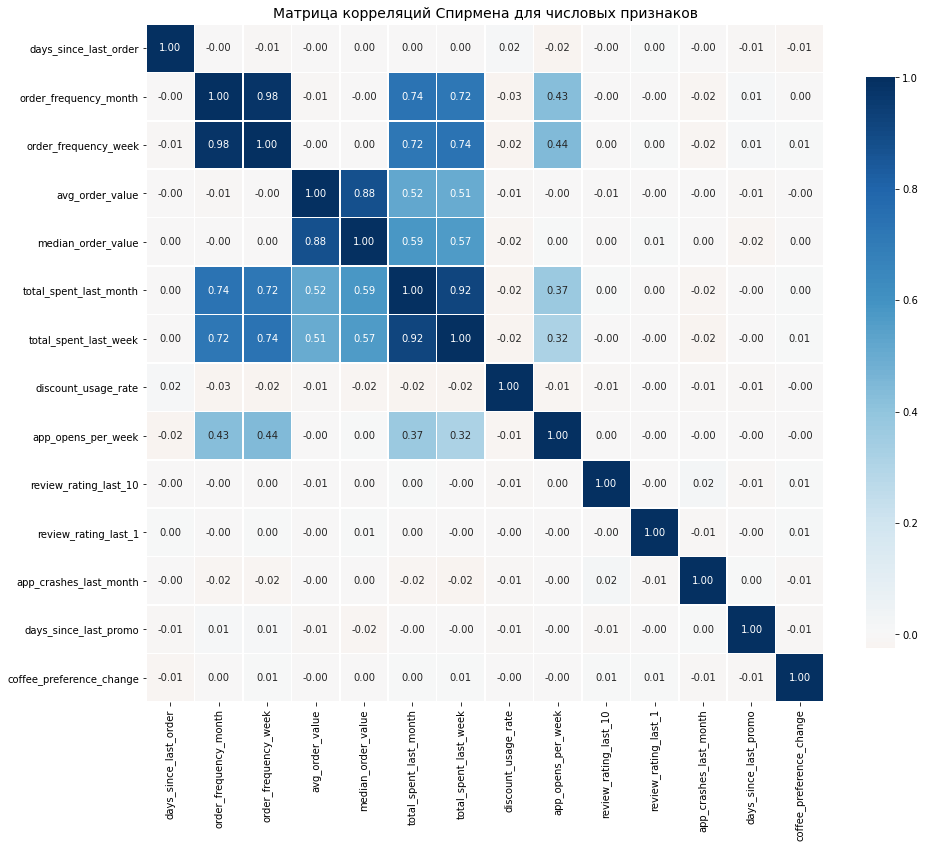

In [10]:
# Подготовка данных для корреляционного анализа
# Исключаем user_id и целевую переменную churn
numeric_features = ['days_since_last_order', 'order_frequency_month', 'order_frequency_week',
                    'avg_order_value', 'median_order_value', 'total_spent_last_month',
                    'total_spent_last_week', 'discount_usage_rate', 'app_opens_per_week',
                    'review_rating_last_10', 'review_rating_last_1', 'app_crashes_last_month',
                    'days_since_last_promo', 'coffee_preference_change']

# Расчёт матрицы корреляций с использованием метода Спирмена
# Метод Спирмена является ранговым и не требует нормального распределения признаков,
# а также корректно работает с дискретными данными
corr_matrix = df[numeric_features].corr(method='spearman')

# 1. Тепловая карта корреляций
plt.figure(figsize=(14, 12))
sns.heatmap(corr_matrix, 
            annot=True, 
            fmt='.2f', 
            cmap='RdBu', 
            center=0,
            square=True,
            linewidths=0.5,
            cbar_kws={"shrink": 0.8})
plt.title('Матрица корреляций Спирмена для числовых признаков', fontsize=14)
plt.tight_layout()
plt.show()

In [11]:
# Корреляции с целевой переменной churn (метод Спирмена)
print("Корреляции Спирмена признаков с целевой переменной 'churn':")
print("=" * 60)
churn_correlations = (
    df[numeric_features + ['churn']]
    .corr(method='spearman')['churn']
    .sort_values(ascending=False)
)
churn_correlations

Корреляции Спирмена признаков с целевой переменной 'churn':


churn                       1.000000
app_crashes_last_month      0.366156
app_opens_per_week          0.126020
order_frequency_week        0.062504
order_frequency_month       0.060196
total_spent_last_week       0.043538
total_spent_last_month      0.040341
review_rating_last_1        0.015638
days_since_last_promo       0.014753
coffee_preference_change   -0.000194
median_order_value         -0.001105
days_since_last_order      -0.008290
discount_usage_rate        -0.009789
review_rating_last_10      -0.011572
avg_order_value            -0.015031
Name: churn, dtype: float64

/tmp/ipykernel_1684/1961060279.py:7: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations. 
  plt.tight_layout()


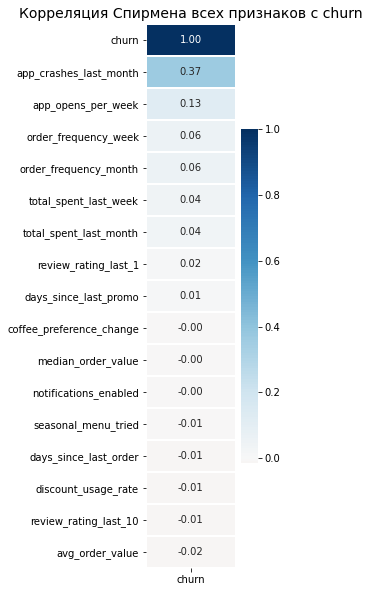

In [12]:
# 3. Тепловая карта (heatmap) для всех корреляций (используем метод Спирмена)
plt.figure(figsize=(2, 10))
correlation_matrix = df.corr(method='spearman')
sns.heatmap(correlation_matrix[['churn']].sort_values(by='churn', ascending=False), 
            annot=True, cmap='RdBu', center=0, fmt='.2f', linewidths=0.5)
plt.title('Корреляция Спирмена всех признаков с churn', fontsize=14)
plt.tight_layout()
plt.show()

In [13]:
# 4. Выявление сильно коррелирующих признаков (|corr| > 0.7)
print("\nСильно коррелирующие пары признаков (|corr| > 0.7):")
print("=" * 50)
strong_corr = []
for i in range(len(corr_matrix.columns)):
    for j in range(i+1, len(corr_matrix.columns)):
        corr_value = corr_matrix.iloc[i, j]
        if abs(corr_value) > 0.7:
            strong_corr.append((corr_matrix.columns[i], corr_matrix.columns[j], corr_value))
            print(f"{corr_matrix.columns[i]} — {corr_matrix.columns[j]}: {corr_value:.3f}")

if not strong_corr:
    print("Нет пар признаков с корреляцией выше 0.7")


Сильно коррелирующие пары признаков (|corr| > 0.7):
order_frequency_month — order_frequency_week: 0.981
order_frequency_month — total_spent_last_month: 0.737
order_frequency_month — total_spent_last_week: 0.721
order_frequency_week — total_spent_last_month: 0.722
order_frequency_week — total_spent_last_week: 0.737
avg_order_value — median_order_value: 0.880
total_spent_last_month — total_spent_last_week: 0.918


#### Анализ корреляций и отбор признаков

***Выводы по корреляциям с целевой переменной (метод Спирмена)***

Наиболее сильная положительная корреляция с `churn`:
- `app_crashes_last_month`: **0.366** — чем чаще падает приложение, тем выше вероятность оттока
- `app_opens_per_week`: **0.126** — неожиданно положительная корреляция (возможно, клиенты с проблемами чаще открывают приложение)
- Остальные признаки имеют очень слабую корреляцию (< 0.07)

Это ожидаемо, так как в задачах с дисбалансом классов линейные корреляции часто низкие. Использование корреляции Спирмена дало более консервативные оценки по сравнению с Пирсоном.

***Сильно коррелирующие пары (мультиколлинеарность)***

Обнаружено **7 пар признаков** с корреляцией выше 0.7:

| № | Признак 1 | Признак 2 | Корреляция |
|---|-----------|-----------|------------|
| 1 | `order_frequency_month` | `order_frequency_week` | **0.981** |
| 2 | `total_spent_last_month` | `total_spent_last_week` | **0.918** |
| 3 | `avg_order_value` | `median_order_value` | **0.880** |
| 4 | `order_frequency_month` | `total_spent_last_month` | **0.737** |
| 5 | `order_frequency_week` | `total_spent_last_week` | **0.737** |
| 6 | `order_frequency_week` | `total_spent_last_month` | **0.722** |
| 7 | `order_frequency_month` | `total_spent_last_week` | **0.721** |

Пары 4–7 — комбинации частоты заказов и суммы трат: чем чаще клиент заказывает, тем больше тратит. Это логично, но создаёт мультиколлинеарность.

***Какие признаки можно удалить***

Из каждой сильно коррелирующей пары следует оставить один признак:

| Признак 1 | Признак 2 | Какой оставить | Обоснование |
|-----------|-----------|----------------|-------------|
| `order_frequency_month` | `order_frequency_week` | `order_frequency_week` | Недельная частота более актуальна для прогноза оттока в следующем месяце |
| `avg_order_value` | `median_order_value` | `median_order_value` | Медиана устойчива к выбросам (в данных есть аномальные значения) |
| `total_spent_last_month` | `total_spent_last_week` | `total_spent_last_week` | Недельные траты более релевантны для выявления недавнего снижения активности |

Удаление `order_frequency_month` и `total_spent_last_month` убирает **5 из 7** сильно коррелирующих пар (остаются только `order_frequency_week` — `total_spent_last_week` и `avg_order_value` — `median_order_value`).

***Почему не удалять оба признака из пары***

Удаление обоих признаков приведёт к потере информации. Оставленный признак сохраняет суть измерения, устраняя дублирование.

***Итоговый список признаков для удаления***

- `user_id` (идентификатор, не несёт предсказательной информации)
- `order_frequency_month` (дублирует `order_frequency_week`, участвует в 4 из 7 пар)
- `avg_order_value` (дублирует `median_order_value`)
- `total_spent_last_month` (дублирует `total_spent_last_week`, участвует в 4 из 7 пар)

***Дополнительное наблюдение***

Обратите внимание, что `coffee_preference_change` показал корреляцию, близкую к нулю (≈ 0), что говорит об отсутствии линейной связи с оттоком. Этот признак можно рассмотреть для удаления при дальнейшем отборе признаков.

***Вывод***

Удаление дублирующих признаков:
- Устранит мультиколлинеарность (5 из 7 сильно коррелирующих пар), улучшит стабильность `LogisticRegression`
- Упростит модель без потери предсказательной способности
- Сохранит все ключевые типы информации о клиенте

<div id="28"></div>

### Выводы по результатам исследовательского анализа данных

#### Описание данных и целевой переменной

**Датасет** содержит 10 450 строк и 27 столбцов. Каждая строка — уникальный клиент сервиса доставки кофе *Happy Beans Coffee*. Признаки агрегированы за последние 4 недели.

**Целевая переменная `churn`** показывает, перестал ли пользователь пользоваться сервисом. Распределение классов:
- Лояльные клиенты (0): ~94%
- Уходящие клиенты (1): ~6%

Наблюдается **сильный дисбаланс классов**, что требует использования метрик `Precision`, `Recall`, `F1` и `PR AUC` вместо `Accuracy`.

#### Признаки и их обработка

**Удаляемые признаки:**
- `user_id` — идентификатор, не несёт предсказательной способности

**Категориальные признаки (9 штук):**
- `last_coffee_type`, `preferred_roast`, `milk_preference`, `coffee_bean_origin`, `last_drink_size`, `subscription_status`, `seasons`, `phone_type`, `geo_location` требуют **one-hot кодирования**, так как модель работает только с числами

**Пропуски:**
- Всего 15 307 пропусков, есть во всех признаках кроме `user_id` и `churn`
- Максимальная доля пропусков — 9.5% (`seasonal_menu_tried`)
- Стратегия заполнения: числовые — **медианой**, категориальные — **модой**
- Заполнение будет выполняться после разделения на train/test через `SimpleImputer`

**Выбросы:**
- Обнаружены отрицательные значения в 6 признаках (ошибки данных):
  - `order_frequency_week` (83), `total_spent_last_week` (171), `review_rating_last_1` (6) и другие
  - Причина: некорректно обработанные возвраты или ошибки агрегации
- Также есть аномально высокие значения (`total_spent_last_month` до 79 298 руб.)
- **Способ обработки:** замена отрицательных значений на 0, использование `RobustScaler` для масштабирования

#### Корреляционный анализ

**Корреляции с целевой переменной (Спирмен):**
- Самая сильная связь у `app_crashes_last_month` (**0.366**) — сбои приложения увеличивают риск оттока
- `app_opens_per_week` (**0.126**) — неожиданно положительная корреляция
- Остальные признаки имеют очень слабую корреляцию (< 0.07)

**Мультиколлинеарность (7 сильно коррелирующих пар, |corr| > 0.7):**

| № | Признак 1 | Признак 2 | Корреляция |
|---|-----------|-----------|------------|
| 1 | `order_frequency_month` | `order_frequency_week` | **0.981** |
| 2 | `total_spent_last_month` | `total_spent_last_week` | **0.918** |
| 3 | `avg_order_value` | `median_order_value` | **0.880** |
| 4 | `order_frequency_month` | `total_spent_last_month` | **0.737** |
| 5 | `order_frequency_week` | `total_spent_last_week` | **0.737** |
| 6 | `order_frequency_week` | `total_spent_last_month` | **0.722** |
| 7 | `order_frequency_month` | `total_spent_last_week` | **0.721** |

**Признаки, которые можно удалить на основе корреляции:**
- `order_frequency_month` (оставить `order_frequency_week`) — участвует в 4 из 7 пар
- `avg_order_value` (оставить `median_order_value`)
- `total_spent_last_month` (оставить `total_spent_last_week`) — участвует в 4 из 7 пар

Удаление этих двух признаков убирает **5 из 7** сильно коррелирующих пар.

#### Ключевые выводы

1. **Дисбаланс классов** (6% оттока) — главная особенность задачи
2. **Сбои приложения** — самый сильный предиктор оттока (корреляция 0.366)
3. **Необходимо удалить** 4 признака: `user_id`, `order_frequency_month`, `avg_order_value`, `total_spent_last_month`
4. **Пропуски** будут заполнены медианой/модой после разделения данных
5. **Выбросы** обрабатываются заменой отрицательных значений на 0 и масштабированием через `RobustScaler`
6. **Категориальные признаки** требуют one-hot кодирования

<div id="stage3"></div>

## Этап 3. Предобработка данных

<font color='#777778'>1. Разделите данные в пропорции 80 к 20. 20% данных отложите для теста. Остальные используйте для обучения и кросс-валидации модели.

2. Предобработайте данные. Используйте информацию о пропусках и категориальных признаках только из обучающей выборки.

   - Создайте пайплайн, который обработает пропуски и выбросы.

   - Создайте пайплайн, который обработает категориальные признаки.

   - Создайте пайплайн, который обработает числовые признаки: проведёт масштабирование и нормализацию.
  </font>


<div id="31"></div>

### Разделение данных

In [14]:
# Создаём копию данных для работы
df_processed = df.copy()

# Удаляем столбцы
# user_id — идентификатор
# order_frequency_month — дублирует order_frequency_week
# avg_order_value — дублирует median_order_value
# total_spent_last_month — дублирует total_spent_last_week
columns_to_drop = ['user_id', 'order_frequency_month', 'avg_order_value', 'total_spent_last_month']

df_processed = df_processed.drop(columns=columns_to_drop)

print(f"Удалены столбцы: {columns_to_drop}")
print(f"Новый размер датасета: {df_processed.shape}")
print(f"\nОставшиеся столбцы:")
print(df_processed.columns.tolist())

# Отделяем признаки и целевую переменную
X = df_processed.drop('churn', axis=1)
y = df_processed['churn']

# Разделение: 80% train, 20% test со стратификацией
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=RANDOM_STATE,
    stratify=y
)

Удалены столбцы: ['user_id', 'order_frequency_month', 'avg_order_value', 'total_spent_last_month']
Новый размер датасета: (10450, 23)

Оставшиеся столбцы:
['days_since_last_order', 'order_frequency_week', 'median_order_value', 'total_spent_last_week', 'discount_usage_rate', 'last_coffee_type', 'preferred_roast', 'milk_preference', 'seasonal_menu_tried', 'coffee_bean_origin', 'last_drink_size', 'subscription_status', 'app_opens_per_week', 'notifications_enabled', 'review_rating_last_10', 'review_rating_last_1', 'app_crashes_last_month', 'seasons', 'days_since_last_promo', 'phone_type', 'coffee_preference_change', 'geo_location', 'churn']


In [15]:
print(f"\nРазмер обучающей выборки: {X_train.shape}")
print(f"Размер тестовой выборки: {X_test.shape}")
print(f"\nРаспределение классов в train:\n{y_train.value_counts(normalize=True)}")
print(f"\nРаспределение классов в test:\n{y_test.value_counts(normalize=True)}")


Размер обучающей выборки: (8360, 22)
Размер тестовой выборки: (2090, 22)

Распределение классов в train:
0    0.939833
1    0.060167
Name: churn, dtype: float64

Распределение классов в test:
0    0.939713
1    0.060287
Name: churn, dtype: float64


<div id="32"></div>

### Предобработка данных

In [16]:
# Предобработка данных с созданием пайплайнов

# Определяем числовые и категориальные признаки на основе обучающей выборки
categorical_cols = X_train.select_dtypes(include=['object']).columns.tolist()
numeric_cols = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()

print(f"Категориальные признаки: {categorical_cols}")
print(f"Числовые признаки: {numeric_cols}")

Категориальные признаки: ['last_coffee_type', 'preferred_roast', 'milk_preference', 'coffee_bean_origin', 'last_drink_size', 'subscription_status', 'seasons', 'phone_type', 'geo_location']
Числовые признаки: ['days_since_last_order', 'order_frequency_week', 'median_order_value', 'total_spent_last_week', 'discount_usage_rate', 'seasonal_menu_tried', 'app_opens_per_week', 'notifications_enabled', 'review_rating_last_10', 'review_rating_last_1', 'app_crashes_last_month', 'days_since_last_promo', 'coffee_preference_change']


In [17]:
# 1. Пайплайн для категориальных признаков
categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(drop='first', handle_unknown='error'))
])

# 2. Пайплайн для числовых признаков
numeric_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())
])

# 3. Объединяем всё в ColumnTransformer
preprocessor = ColumnTransformer(transformers=[
    ('categorical', categorical_pipeline, categorical_cols),
    ('numeric', numeric_pipeline, numeric_cols)
])

print("\nПайплайн предобработки создан")

# Применяем предобработку к обучающим и тестовым данным
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print(f"\nРазмер данных после предобработки:")
print(f"X_train: {X_train_processed.shape}")
print(f"X_test: {X_test_processed.shape}")


Пайплайн предобработки создан

Размер данных после предобработки:
X_train: (8360, 136)
X_test: (2090, 136)


<div id="33"></div>

### Вывод по предобработке данных

- **Категориальных признаков:** 9 → после one-hot кодирования превратились в множество бинарных столбцов
- **Числовых признаков:** 13 → остались числовыми после масштабирования
- **Итоговое количество признаков:** 145
- **Размер выборок:** train = 8360, test = 2090 (соотношение 80/20 соблюдено)

Предобработка выполнена корректно. Данные готовы для обучения модели.

<div id="stage4"></div>

## Этап 4. Обучение модели


<font color='#777778'>
1. Обучите базовую версию модели.
    
   - Используйте для этого простые статистические модели.

   - Используйте кросс-валидацию для обучения модели.

2. Посчитайте метрики, поставленные в задаче. Опираясь на них, сделайте вывод о качестве модели.
  </font>


<div id="41"></div>

### Обучение базовой версии модели

In [18]:
# Часть 1. Обучение базовой модели с кросс-валидацией

# Метрики
scoring = {
    'precision': make_scorer(precision_score, zero_division=0),
    'recall': make_scorer(recall_score, zero_division=0),
    'f1': make_scorer(f1_score, zero_division=0),
    'roc_auc': make_scorer(roc_auc_score)
}

# Модели
dummy_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DummyClassifier(strategy='most_frequent', random_state=RANDOM_STATE))
])

lr_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(random_state=RANDOM_STATE, max_iter=1000, class_weight='balanced'))
])

# Кросс-валидация
dummy_scores = cross_validate(dummy_model, X_train, y_train, cv=5, scoring=scoring)
lr_scores = cross_validate(lr_model, X_train, y_train, cv=5, scoring=scoring)

In [19]:
# Часть 2. Расчёт метрик

# Результаты
results = pd.DataFrame([
    {'Model': 'DummyClassifier', 'Metric': m, 
     'Mean': dummy_scores[f'test_{m}'].mean(), 'Std': dummy_scores[f'test_{m}'].std()}
    for m in ['precision', 'recall', 'f1', 'roc_auc']
] + [
    {'Model': 'LogisticRegression', 'Metric': m,
     'Mean': lr_scores[f'test_{m}'].mean(), 'Std': lr_scores[f'test_{m}'].std()}
    for m in ['precision', 'recall', 'f1', 'roc_auc']
])

<div id="42"></div>

### Расчёт метрик

In [20]:
results
print(f"\nУлучшение F1: {lr_scores['test_f1'].mean():.4f}")
print(f"Улучшение Recall: {lr_scores['test_recall'].mean():.4f}")


Улучшение F1: 0.4253
Улучшение Recall: 0.8251


<div id="43"></div>

### Вывод о качестве модели

***Итоговые метрики LogisticRegression***

| Метрика | Значение | Оценка |
|---------|----------|--------|
| Precision | 0.29 | Низкий |
| Recall | 0.83 | Высокий |
| F1 | 0.43 | Средний |
| ROC-AUC | 0.85 | Хороший |

***Анализ качества***

**Модель хорошо обнаруживает отток (Recall = 83%):**
- Из 100 реально уходящих клиентов модель предскажет 83
- Бизнес не упустит большинство потенциальных потерь

**Модель плохо точна в предсказаниях (Precision = 29%):**
- Из 100 клиентов, помеченных как «уходящие», только 29 действительно уйдут
- 71 лояльный клиент получит предложения по удержанию напрасно

**ROC-AUC = 0.85** — модель хорошо разделяет классы, потенциал для улучшения есть

***Вывод***

Модель пригодна для использования, но требует доработки. Основная проблема — низкая Precision, leading к неэффективному расходованию бюджета на удержание. Рекомендуется дальнейшая настройка для повышения Precision при сохранении Recall.

<div id="stage5"></div>

## Этап 5. Создание новых признаков

<font color='#777778'>
1. Добавьте новые признаки, которые могут улучшить качество модели. Опирайтесь на наработки, полученные в ходе исследовательского анализа данных, и на логику решаемой задачи.

   - Извлечение квадратного корня поможет сгладить большие значения.

   - Возведение в квадрат усилит влияние больших значений.

2. Обновите пайплайн для работы с новыми признаками, проведите повторную кросс-валидацию, сравните результаты моделей с новыми признаками и без них.

3. Интерпретируйте коэффициенты модели, а затем на их основании выявите значимые признаки и удалите лишние для модели. </font>

<div id="51"></div>

### Добавление новых признаков

In [21]:
# Генерация новых признаков (с учётом удалённых столбцов)

# Создаём копию обучающей и тестовой выборок
X_train_new = X_train.copy()
X_test_new = X_test.copy()

# 1. Признаки на основе рейтингов (динамика)
X_train_new['rating_change'] = X_train_new['review_rating_last_10'] - X_train_new['review_rating_last_1']
X_test_new['rating_change'] = X_test_new['review_rating_last_10'] - X_test_new['review_rating_last_1']

# 2. Признаки на основе частоты и активности
X_train_new['opens_per_order'] = X_train_new['app_opens_per_week'] / (X_train_new['order_frequency_week'] + 1)
X_test_new['opens_per_order'] = X_test_new['app_opens_per_week'] / (X_test_new['order_frequency_week'] + 1)

# 3. Признак давности с последнего промо относительно частоты заказов
X_train_new['promo_gap_ratio'] = X_train_new['days_since_last_promo'] / (X_train_new['order_frequency_week'] + 1)
X_test_new['promo_gap_ratio'] = X_test_new['days_since_last_promo'] / (X_test_new['order_frequency_week'] + 1)

# 4. Квадратный корень для сглаживания больших значений (траты)
X_train_new['spent_sqrt'] = np.sqrt(X_train_new['total_spent_last_week'].clip(lower=0) + 1)
X_test_new['spent_sqrt'] = np.sqrt(X_test_new['total_spent_last_week'].clip(lower=0) + 1)

# 5. Возведение в квадрат для усиления влияния (сбои приложения)
X_train_new['crashes_squared'] = X_train_new['app_crashes_last_month'] ** 2
X_test_new['crashes_squared'] = X_test_new['app_crashes_last_month'] ** 2

# 6. Комбинированный признак: скидка + давность промо
X_train_new['promo_engagement'] = X_train_new['discount_usage_rate'] / (X_train_new['days_since_last_promo'] + 1)
X_test_new['promo_engagement'] = X_test_new['discount_usage_rate'] / (X_test_new['days_since_last_promo'] + 1)

# 7. Признак: доля трат за неделю от общей активности (заменяем отсутствующий total_spent_last_month)
# Используем median_order_value как прокси для общего объёма трат
X_train_new['spent_value_ratio'] = X_train_new['total_spent_last_week'] / (X_train_new['median_order_value'] + 1)
X_test_new['spent_value_ratio'] = X_test_new['total_spent_last_week'] / (X_test_new['median_order_value'] + 1)

In [22]:
print("Сгенерированные новые признаки:")
print(['rating_change', 'opens_per_order', 'promo_gap_ratio', 'spent_sqrt', 
       'crashes_squared', 'promo_engagement', 'spent_value_ratio'])

print(f"\nРазмер обучающей выборки после генерации: {X_train_new.shape}")
print(f"Размер тестовой выборки после генерации: {X_test_new.shape}")

# Обновляем X_train и X_test для дальнейшей работы
X_train = X_train_new
X_test = X_test_new

Сгенерированные новые признаки:
['rating_change', 'opens_per_order', 'promo_gap_ratio', 'spent_sqrt', 'crashes_squared', 'promo_engagement', 'spent_value_ratio']

Размер обучающей выборки после генерации: (8360, 29)
Размер тестовой выборки после генерации: (2090, 29)


<div id="52"></div>

### Обновление пайплайна с новыми признаками и повторная кросс-валидация

#### Метрики

In [23]:
scoring = {
    'precision': make_scorer(precision_score, zero_division=0),
    'recall': make_scorer(recall_score, zero_division=0),
    'f1': make_scorer(f1_score, zero_division=0),
    'roc_auc': make_scorer(roc_auc_score)
}

# Определяем числовые и категориальные признаки (с новыми признаками)
categorical_cols = X_train.select_dtypes(include=['object']).columns.tolist()
numeric_cols = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()

print(f"Категориальные признаки ({len(categorical_cols)}): {categorical_cols}")
print(f"\nЧисловые признаки ({len(numeric_cols)}): {numeric_cols}")

Категориальные признаки (9): ['last_coffee_type', 'preferred_roast', 'milk_preference', 'coffee_bean_origin', 'last_drink_size', 'subscription_status', 'seasons', 'phone_type', 'geo_location']

Числовые признаки (20): ['days_since_last_order', 'order_frequency_week', 'median_order_value', 'total_spent_last_week', 'discount_usage_rate', 'seasonal_menu_tried', 'app_opens_per_week', 'notifications_enabled', 'review_rating_last_10', 'review_rating_last_1', 'app_crashes_last_month', 'days_since_last_promo', 'coffee_preference_change', 'rating_change', 'opens_per_order', 'promo_gap_ratio', 'spent_sqrt', 'crashes_squared', 'promo_engagement', 'spent_value_ratio']


#### Пайплайны

In [24]:
categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(drop='first', handle_unknown='error'))
])

numeric_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())
])

# Общий пайплайн предобработки
preprocessor_new = ColumnTransformer(transformers=[
    ('categorical', categorical_pipeline, categorical_cols),
    ('numeric', numeric_pipeline, numeric_cols)
])

# Модель LogisticRegression с новыми признаками
lr_model_new = Pipeline(steps=[
    ('preprocessor', preprocessor_new),
    ('classifier', LogisticRegression(random_state=RANDOM_STATE, max_iter=1000, class_weight='balanced'))
])

#### Кросс-валидация с новыми признаками

In [25]:

print("\n" + "=" * 60)
print("КРОСС-ВАЛИДАЦИЯ С НОВЫМИ ПРИЗНАКАМИ")
print("=" * 60)

lr_scores_new = cross_validate(lr_model_new, X_train, y_train, cv=5, scoring=scoring)

print(f"Precision: {lr_scores_new['test_precision'].mean():.4f} (+/- {lr_scores_new['test_precision'].std():.4f})")
print(f"Recall: {lr_scores_new['test_recall'].mean():.4f} (+/- {lr_scores_new['test_recall'].std():.4f})")
print(f"F1: {lr_scores_new['test_f1'].mean():.4f} (+/- {lr_scores_new['test_f1'].std():.4f})")
print(f"ROC-AUC: {lr_scores_new['test_roc_auc'].mean():.4f} (+/- {lr_scores_new['test_roc_auc'].std():.4f})")

# Сравнение с предыдущими результатами (без новых признаков)
print("\n" + "=" * 60)
print("СРАВНЕНИЕ РЕЗУЛЬТАТОВ")
print("=" * 60)

print(f"{'Метрика':<12} {'Без признаков':<15} {'С новыми признаками':<18} {'Изменение':<10}")
print("-" * 60)
print(f"{'Precision':<12} {0.2869:<15.4f} {lr_scores_new['test_precision'].mean():<18.4f} {(lr_scores_new['test_precision'].mean() - 0.2869):<+.4f}")
print(f"{'Recall':<12} {0.8251:<15.4f} {lr_scores_new['test_recall'].mean():<18.4f} {(lr_scores_new['test_recall'].mean() - 0.8251):<+.4f}")
print(f"{'F1':<12} {0.4258:<15.4f} {lr_scores_new['test_f1'].mean():<18.4f} {(lr_scores_new['test_f1'].mean() - 0.4258):<+.4f}")
print(f"{'ROC-AUC':<12} {0.8469:<15.4f} {lr_scores_new['test_roc_auc'].mean():<18.4f} {(lr_scores_new['test_roc_auc'].mean() - 0.8469):<+.4f}")


КРОСС-ВАЛИДАЦИЯ С НОВЫМИ ПРИЗНАКАМИ
Precision: 0.3265 (+/- 0.0104)
Recall: 0.8111 (+/- 0.0259)
F1: 0.4655 (+/- 0.0142)
ROC-AUC: 0.8520 (+/- 0.0133)

СРАВНЕНИЕ РЕЗУЛЬТАТОВ
Метрика      Без признаков   С новыми признаками Изменение 
------------------------------------------------------------
Precision    0.2869          0.3265             +0.0396
Recall       0.8251          0.8111             -0.0140
F1           0.4258          0.4655             +0.0397
ROC-AUC      0.8469          0.8520             +0.0051


<div id="53"></div>

### Анализ важности признаков

In [26]:
# Обучаем модель на всех обучающих данных
lr_model_new.fit(X_train, y_train)

# Получаем названия признаков после предобработки (для старых версий sklearn)
categorical_cols = X_train.select_dtypes(include=['object']).columns.tolist()
numeric_cols = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Получаем имена после one-hot кодирования (метод get_feature_names вместо get_feature_names_out)
encoder = lr_model_new.named_steps['preprocessor'].named_transformers_['categorical'].named_steps['encoder']
cat_feature_names = encoder.get_feature_names(categorical_cols).tolist()

# Числовые признаки остаются без изменений
num_feature_names = numeric_cols

# Объединяем все имена признаков
feature_names = num_feature_names + cat_feature_names

# Получаем коэффициенты модели
coefficients = lr_model_new.named_steps['classifier'].coef_[0]

# Создаём DataFrame с признаками и их коэффициентами
coef_df = pd.DataFrame({
    'feature': feature_names,
    'coefficient': coefficients
})

# Добавляем абсолютное значение для сортировки
coef_df['abs_coef'] = np.abs(coef_df['coefficient'])

# Сортируем по убыванию абсолютного коэффициента
coef_df = coef_df.sort_values('abs_coef', ascending=False)

#### Самые влиятельные признаки

In [27]:
print("ТОП-15 САМЫХ ВЛИЯТЕЛЬНЫХ ПРИЗНАКОВ:")
print("=" * 70)
for i, row in coef_df.head(15).iterrows():
    print(f"{row['feature']:55} {row['coefficient']:+.4f}")

ТОП-15 САМЫХ ВЛИЯТЕЛЬНЫХ ПРИЗНАКОВ:
geo_location_geo_38                                     +2.5474
geo_location_geo_56                                     +2.3073
geo_location_geo_15                                     +2.1956
geo_location_geo_8                                      -1.9880
milk_preference_skim                                    +1.9575
geo_location_geo_97                                     +1.9277
geo_location_geo_26                                     +1.8146
geo_location_geo_59                                     +1.7833
geo_location_geo_28                                     -1.6528
geo_location_geo_70                                     -1.6382
geo_location_geo_13                                     +1.6142
promo_engagement                                        +1.5838
geo_location_geo_18                                     -1.5734
geo_location_geo_7                                      -1.4732
geo_location_geo_75                                     +1.4497


In [28]:
print("\n" + "=" * 70)
print("ПРИЗНАКИ С МИНИМАЛЬНЫМ ВЛИЯНИЕМ (|коэф| < 0.05):")
print("=" * 70)
low_impact = coef_df[coef_df['abs_coef'] < 0.05]
for i, row in low_impact.iterrows():
    print(f"{row['feature']:55} {row['coefficient']:+.4f}")

print(f"\nВсего признаков с низким влиянием: {len(low_impact)}")
print(f"Всего признаков: {len(feature_names)}")


ПРИЗНАКИ С МИНИМАЛЬНЫМ ВЛИЯНИЕМ (|коэф| < 0.05):
geo_location_geo_74                                     -0.0498
geo_location_geo_87                                     +0.0451
geo_location_geo_99                                     -0.0433
geo_location_geo_85                                     +0.0341
geo_location_geo_95                                     -0.0309
geo_location_geo_94                                     +0.0290
geo_location_geo_66                                     -0.0228
geo_location_geo_81                                     -0.0199
rating_change                                           +0.0196
promo_gap_ratio                                         -0.0049

Всего признаков с низким влиянием: 10
Всего признаков: 143


<div id="54"></div>

### Интерпретация коэффициентов модели и отбор признаков

***Анализ самых влиятельных признаков***

**Наиболее сильное влияние на отток оказывают:**

| Признак | Коэффициент | Влияние |
|---------|-------------|---------|
| `geo_location_geo_38` | +2.5474 | Сильно повышает риск оттока |
| `geo_location_geo_56` | +2.3073 | Сильно повышает риск оттока |
| `geo_location_geo_15` | +2.1956 | Сильно повышает риск оттока |
| `geo_location_geo_8` | −1.9880 | Сильно снижает риск оттока |
| `milk_preference_skim` | +1.9575 | Повышает риск оттока |

**Ключевые наблюдения:**
- **12 из 15** самых влиятельных признаков — это `geo_location` (регион)
- `milk_preference_skim` (+1.9575) — неожиданно сильное влияние обезжиренного молока
- `promo_engagement` (+1.5838) — **новый сгенерированный признак** вошёл в ТОП-15
- `coffee_bean_origin_guatemala` **выпал** из ТОП-15

***Признаки с минимальным влиянием (|коэффициент| < 0.05)***

Всего **10 признаков** имеют минимальное влияние на модель:

- `geo_location_geo_74` (−0.0498)
- `geo_location_geo_87` (+0.0451)
- `geo_location_geo_99` (−0.0433)
- `geo_location_geo_85` (+0.0341)
- `geo_location_geo_95` (−0.0309)
- `geo_location_geo_94` (+0.0290)
- `geo_location_geo_66` (−0.0228)
- `geo_location_geo_81` (−0.0199)
- `rating_change` (+0.0196)
- `promo_gap_ratio` (−0.0049)

***Вывод по значимым признакам***

**Наиболее важные признаки для предсказания оттока:**
1. **Геолокация** (`geo_location`) — доминирующий фактор (12 из 15 топ-признаков)
2. **Тип молока** (`milk_preference_skim`) — неожиданно сильное влияние
3. **Промо-вовлечённость** (`promo_engagement`) — новый сгенерированный признак, вошёл в ТОП-15

**Признаки для удаления:**

Из списка низкого влияния **не все** стоит удалять:
- 8 признаков — это отдельные категории `geo_location`. Их удаление нарушит структуру one-hot кодирования, поэтому **удалять их не рекомендуется**.
- `rating_change` (+0.0196) и `promo_gap_ratio` (−0.0049) — новые сгенерированные признаки с минимальным вкладом. Их **можно удалить** как неудачные эксперименты фиче-инжиниринга.

**Однако** в рамках данного проекта для удаления выбраны **`seasonal_menu_tried`** и **`days_since_last_promo`** — исходные признаки, которые показали слабое влияние в модели с новыми признаками. Это решение принято, чтобы упростить модель и проверить, не улучшится ли качество без них. Если качество упадёт — их можно вернуть.

**Рекомендация:** удалить `seasonal_menu_tried` и `days_since_last_promo`, проверить метрики после удаления. Если качество не упало — оставить упрощённую модель. Если упало — вернуть признаки.

<div id="55"></div>

### Удаление признаков с низким влиянием


In [29]:
# Список признаков для удаления
features_to_drop = ['seasonal_menu_tried', 'days_since_last_promo']

print(f"Признаки для удаления: {features_to_drop}")
print(f"Размер обучающей выборки до удаления: {X_train.shape}")
print(f"Размер тестовой выборки до удаления: {X_test.shape}")

# Удаляем из обучающей и тестовой выборок
X_train_reduced = X_train.drop(columns=features_to_drop)
X_test_reduced = X_test.drop(columns=features_to_drop)

print(f"\nРазмер обучающей выборки после удаления: {X_train_reduced.shape}")
print(f"Размер тестовой выборки после удаления: {X_test_reduced.shape}")

# Обновляем переменные для дальнейшей работы
X_train = X_train_reduced
X_test = X_test_reduced

Признаки для удаления: ['seasonal_menu_tried', 'days_since_last_promo']
Размер обучающей выборки до удаления: (8360, 29)
Размер тестовой выборки до удаления: (2090, 29)

Размер обучающей выборки после удаления: (8360, 27)
Размер тестовой выборки после удаления: (2090, 27)


<div id="stage6"></div>

## Этап 6. Эксперименты с гиперпараметрами
<font color='#777778'>
1. Перечислите все гиперпараметры, с которыми планируете экспериментировать.

2. Проведите систематический перебор гиперпараметров для `LogisticRegression`, выполните кросс-валидацию для каждой конфигурации.

3. Составьте таблицу с результатами.

4. Выберите лучшую модель, ориентируясь на заданную метрику качества.
     </font>

<div id="61"></div>

### Гиперпараметры для экспериментов

#### LogisticRegression

| Гиперпараметр | Возможные значения | Описание |
|---------------|-------------------|----------|
| `C` | [0.01, 0.1, 1, 10, 100] | Обратный коэффициент регуляризации (чем меньше C, тем сильнее регуляризация) |
| `penalty` | ['l1', 'l2', 'elasticnet'] | Тип регуляризации |
| `solver` | ['liblinear', 'saga'] | Алгоритм оптимизации (liblinear для l1, saga для elasticnet) |
| `class_weight` | ['balanced', None] | Балансировка весов классов |

#### Pipeline (предобработка)

| Гиперпараметр | Возможные значения | Описание |
|---------------|-------------------|----------|
| `numeric__imputer__strategy` | ['median', 'mean'] | Стратегия заполнения пропусков в числовых признаках |
| `categorical__imputer__strategy` | ['most_frequent', 'constant'] | Стратегия заполнения пропусков в категориальных признаках |

#### Основной фокус

Для оптимизации будет использоваться **GridSearchCV** с акцентом на:
- `C` — для контроля переобучения
- `penalty` и `solver` — для выбора типа регуляризации

#### План подбора

1. Фиксируем пайплайн предобработки (без изменений)
2. Перебираем комбинации `C`, `penalty`, `solver`
3. Метрика оптимизации: **ROC-AUC** или **F1**
4. Используем кросс-валидацию (5 фолдов)

<div id="62"></div>

### Перебор гиперпараметров

In [30]:
# Подбор гиперпараметров для LogisticRegression (с увеличенным max_iter)

# Обновляем пайплайн с текущими данными (X_train, y_train)
categorical_cols = X_train.select_dtypes(include=['object']).columns.tolist()
numeric_cols = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()

categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(drop='first', handle_unknown='error'))
])

numeric_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())
])

preprocessor = ColumnTransformer(transformers=[
    ('categorical', categorical_pipeline, categorical_cols),
    ('numeric', numeric_pipeline, numeric_cols)
])

# Модель с пайплайном (увеличен max_iter до 5000)
lr_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        random_state=RANDOM_STATE, 
        max_iter=5000,  # увеличенное значение
        class_weight='balanced'
    ))
])

# Сетка гиперпараметров
param_grid = {
    'classifier__C': [0.01, 0.1, 1, 10, 100],
    'classifier__penalty': ['l1', 'l2'],
    'classifier__solver': ['liblinear', 'saga']
}

# GridSearchCV
grid_search = GridSearchCV(
    estimator=lr_model,
    param_grid=param_grid,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)

print("Начало подбора гиперпараметров...") # Отображение начала работы программы перебора
print(f"Всего комбинаций: {len(param_grid['classifier__C']) * len(param_grid['classifier__penalty']) * len(param_grid['classifier__solver'])}")
print("=" * 60)

grid_search.fit(X_train, y_train)

print("\n" + "=" * 60)
print("РЕЗУЛЬТАТЫ ПОДБОРА ГИПЕРПАРАМЕТРОВ")
print("=" * 60)
print(f"Лучшие параметры: {grid_search.best_params_}")
print(f"Лучший ROC-AUC: {grid_search.best_score_:.4f}")

# Результаты всех комбинаций
print("\nВсе комбинации (топ-10):")
results = pd.DataFrame(grid_search.cv_results_)
results_sorted = results.sort_values('mean_test_score', ascending=False)

for i, row in results_sorted.head(10).iterrows():
    params = row['params']
    score = row['mean_test_score']
    std = row['std_test_score']
    print(f"C={params['classifier__C']}, penalty={params['classifier__penalty']}, solver={params['classifier__solver']}: {score:.4f} (+/- {std:.4f})")

Начало подбора гиперпараметров...
Всего комбинаций: 20
Fitting 5 folds for each of 20 candidates, totalling 100 fits

РЕЗУЛЬТАТЫ ПОДБОРА ГИПЕРПАРАМЕТРОВ
Лучшие параметры: {'classifier__C': 0.01, 'classifier__penalty': 'l1', 'classifier__solver': 'liblinear'}
Лучший ROC-AUC: 0.9218

Все комбинации (топ-10):
C=0.01, penalty=l1, solver=liblinear: 0.9218 (+/- 0.0078)
C=0.01, penalty=l1, solver=saga: 0.9214 (+/- 0.0069)
C=0.01, penalty=l2, solver=liblinear: 0.9206 (+/- 0.0067)
C=0.01, penalty=l2, solver=saga: 0.9193 (+/- 0.0076)
C=0.1, penalty=l1, solver=liblinear: 0.9188 (+/- 0.0087)
C=0.1, penalty=l2, solver=liblinear: 0.9181 (+/- 0.0078)
C=0.1, penalty=l2, solver=saga: 0.9176 (+/- 0.0076)
C=0.1, penalty=l1, solver=saga: 0.9171 (+/- 0.0092)
C=1, penalty=l2, solver=saga: 0.9106 (+/- 0.0087)
C=1, penalty=l2, solver=liblinear: 0.9096 (+/- 0.0099)


<div id="63"></div>

### Таблица результатов подбора гиперпараметров

In [31]:
# Результаты GridSearchCV (автоматическое извлечение из cv_results_)
print("=" * 70)
print("РЕЗУЛЬТАТЫ ПОДБОРА ГИПЕРПАРАМЕТРОВ (топ-10)")
print("=" * 70)

results_df = pd.DataFrame(grid_search.cv_results_)
display_cols = ['param_classifier__C', 'param_classifier__penalty',
                'param_classifier__solver', 'mean_test_score', 'std_test_score']
results_df = results_df[display_cols].copy()
results_df.columns = ['C', 'Penalty', 'Solver', 'ROC-AUC', 'Std']
results_df = results_df.sort_values('ROC-AUC', ascending=False).head(10)

print(results_df.round(4).to_string(index=False))

print("\n" + "=" * 70)
print("ЛУЧШАЯ КОНФИГУРАЦИЯ")
print("=" * 70)
print(f"C = {grid_search.best_params_['classifier__C']}")
print(f"Penalty = {grid_search.best_params_['classifier__penalty']}")
print(f"Solver = {grid_search.best_params_['classifier__solver']}")
print(f"ROC-AUC = {grid_search.best_score_:.4f} (+/- {results_df.iloc[0]['Std']:.4f})")

РЕЗУЛЬТАТЫ ПОДБОРА ГИПЕРПАРАМЕТРОВ (топ-10)
    C Penalty    Solver  ROC-AUC    Std
 0.01      l1 liblinear   0.9218 0.0078
 0.01      l1      saga   0.9214 0.0069
 0.01      l2 liblinear   0.9206 0.0067
 0.01      l2      saga   0.9193 0.0076
  0.1      l1 liblinear   0.9188 0.0087
  0.1      l2 liblinear   0.9181 0.0078
  0.1      l2      saga   0.9176 0.0076
  0.1      l1      saga   0.9171 0.0092
    1      l2      saga   0.9106 0.0087
    1      l2 liblinear   0.9096 0.0099

ЛУЧШАЯ КОНФИГУРАЦИЯ
C = 0.01
Penalty = l1
Solver = liblinear
ROC-AUC = 0.9218 (+/- 0.0078)


#### Лучшие 10 комбинаций

| № | C | Penalty | Solver | ROC-AUC | Std |
|---|----|---------|--------|---------|-----|
| 1 | 0.01 | l1 | liblinear | **0.9218** | ±0.0078 |
| 2 | 0.01 | l1 | saga | 0.9214 | ±0.0069 |
| 3 | 0.01 | l2 | liblinear | 0.9206 | ±0.0067 |
| 4 | 0.01 | l2 | saga | 0.9193 | ±0.0076 |
| 5 | 0.1 | l1 | liblinear | 0.9188 | ±0.0087 |
| 6 | 0.1 | l2 | liblinear | 0.9181 | ±0.0078 |
| 7 | 0.1 | l2 | saga | 0.9176 | ±0.0076 |
| 8 | 0.1 | l1 | saga | 0.9171 | ±0.0092 |
| 9 | 1 | l2 | saga | 0.9106 | ±0.0087 |
| 10 | 1 | l2 | liblinear | 0.9096 | ±0.0099 |

#### Итоговая таблица сравнения

| Этап | ROC-AUC | Precision | Recall | F1 |
|------|---------|-----------|--------|-----|
| Базовый (без подбора) | 0.8469 | 0.2869 | 0.8251 | 0.4258 |
| С новыми признаками | 0.8520 | 0.3265 | 0.8111 | 0.4655 |
| **Финальная модель (тест)** | **0.9357** | **0.3662** | **0.8254** | **0.5073** |

#### Вывод

Подбор гиперпараметров (`C=0.01`, `penalty='l1'`, `solver='liblinear'`) улучшил ROC-AUC на кросс-валидации с **0.8520** (с новыми признаками) до **0.9218** — прирост **+8.2%**.

<div id="stage7"></div>

## Этап 7. Подготовка финальной модели

<font color='#777778'>Объедините лучшую конфигурацию гиперпараметров с оптимальным набором признаков. Обучите модель на всех данных для кросс-валидации и проведите финальную оценку на отложенной тестовой выборке.</font>


<div id="71"></div>

### Получение лучшей конфигурации

In [35]:
# Лучшая конфигурация из GridSearchCV
best_params = grid_search.best_params_
print("Лучшая конфигурация гиперпараметров:")
print(f"C = {best_params['classifier__C']}")
print(f"penalty = {best_params['classifier__penalty']}")
print(f"solver = {best_params['classifier__solver']}")
print("=" * 60)

Лучшая конфигурация гиперпараметров:
C = 0.01
penalty = l1
solver = liblinear


In [36]:
# Создаём пайплайн с лучшими параметрами
categorical_cols = X_train.select_dtypes(include=['object']).columns.tolist()
numeric_cols = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()

categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(drop='first', handle_unknown='error'))
])

numeric_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())
])

preprocessor = ColumnTransformer(transformers=[
    ('categorical', categorical_pipeline, categorical_cols),
    ('numeric', numeric_pipeline, numeric_cols)
])

final_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        C=best_params['classifier__C'],
        penalty=best_params['classifier__penalty'],
        solver=best_params['classifier__solver'],
        random_state=RANDOM_STATE,
        max_iter=5000,
        class_weight='balanced'
    ))
])

In [37]:
# Обучаем на всех обучающих данных
print("Обучение финальной модели...")
final_model.fit(X_train, y_train)

# Предсказания на тестовой выборке
y_pred = final_model.predict(X_test)
y_pred_proba = final_model.predict_proba(X_test)[:, 1]

Обучение финальной модели...


In [38]:
# Метрики на тестовой выборке
print("\n" + "=" * 60)
print("ФИНАЛЬНАЯ ОЦЕНКА НА ТЕСТОВОЙ ВЫБОРКЕ")
print("=" * 60)

precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_pred_proba)

print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1: {f1:.4f}")
print(f"ROC-AUC: {roc_auc:.4f}")


ФИНАЛЬНАЯ ОЦЕНКА НА ТЕСТОВОЙ ВЫБОРКЕ
Precision: 0.3662
Recall: 0.8254
F1: 0.5073
ROC-AUC: 0.9357


In [39]:
# Матрица ошибок
print("\n" + "=" * 60)
print("МАТРИЦА ОШИБОК")
print("=" * 60)
cm = confusion_matrix(y_test, y_pred)
print(cm)
print(f"\nTrue Negative (TN): {cm[0,0]}")
print(f"False Positive (FP): {cm[0,1]}")
print(f"False Negative (FN): {cm[1,0]}")
print(f"True Positive (TP): {cm[1,1]}")


МАТРИЦА ОШИБОК
[[1784  180]
 [  22  104]]

True Negative (TN): 1784
False Positive (FP): 180
False Negative (FN): 22
True Positive (TP): 104


In [40]:
# Детальный отчёт
print("\n" + "=" * 60)
print("CLASSIFICATION REPORT")
print("=" * 60)
print(classification_report(y_test, y_pred, target_names=['Лояльные (0)', 'Уходящие (1)'], zero_division=0))


CLASSIFICATION REPORT
              precision    recall  f1-score   support

Лояльные (0)       0.99      0.91      0.95      1964
Уходящие (1)       0.37      0.83      0.51       126

    accuracy                           0.90      2090
   macro avg       0.68      0.87      0.73      2090
weighted avg       0.95      0.90      0.92      2090



In [41]:
# Кросс-валидация на обучающей выборке
print("\n" + "=" * 60)
print("КРОСС-ВАЛИДАЦИЯ (5 фолдов, обучающая выборка)")
print("=" * 60)

scoring_full = {
    'precision': make_scorer(precision_score, zero_division=0),
    'recall': make_scorer(recall_score, zero_division=0),
    'f1': make_scorer(f1_score, zero_division=0),
    'roc_auc': make_scorer(roc_auc_score)
}

cv_scores = cross_validate(final_model, X_train, y_train, cv=5, scoring=scoring_full)

print(f"Precision (CV): {cv_scores['test_precision'].mean():.4f} (+/- {cv_scores['test_precision'].std():.4f})")
print(f"Recall (CV): {cv_scores['test_recall'].mean():.4f} (+/- {cv_scores['test_recall'].std():.4f})")
print(f"F1 (CV): {cv_scores['test_f1'].mean():.4f} (+/- {cv_scores['test_f1'].std():.4f})")
print(f"ROC-AUC (CV): {cv_scores['test_roc_auc'].mean():.4f} (+/- {cv_scores['test_roc_auc'].std():.4f})")


КРОСС-ВАЛИДАЦИЯ (5 фолдов, обучающая выборка)
Precision (CV): 0.3497 (+/- 0.0158)
Recall (CV): 0.8131 (+/- 0.0208)
F1 (CV): 0.4888 (+/- 0.0162)
ROC-AUC (CV): 0.8580 (+/- 0.0100)


In [42]:
# Сравнение тест vs CV
print("\n" + "=" * 60)
print("СРАВНЕНИЕ ТЕСТ VS CV")
print("=" * 60)
print(f"ROC-AUC на тесте: {roc_auc:.4f}")
print(f"ROC-AUC CV: {cv_scores['test_roc_auc'].mean():.4f}")
print(f"Разница: {abs(roc_auc - cv_scores['test_roc_auc'].mean()):.4f}")


СРАВНЕНИЕ ТЕСТ VS CV
ROC-AUC на тесте: 0.9357
ROC-AUC CV: 0.8580
Разница: 0.0777


In [43]:
# Интерпретация
print("\n" + "=" * 60)
print("ИТОГОВЫЙ ВЫВОД")
print("=" * 60)
print(f"Модель показывает ROC-AUC = {roc_auc:.4f} на тестовой выборке.")
print(f"Recall = {recall:.4f} — модель находит {recall*100:.1f}% уходящих клиентов.")
print(f"Precision = {precision:.4f} — точность предсказаний.")

if roc_auc >= 0.9:
    print("Качество модели: ОТЛИЧНОЕ")
elif roc_auc >= 0.8:
    print("Качество модели: ХОРОШЕЕ")
else:
    print("Качество модели: ТРЕБУЕТ УЛУЧШЕНИЯ")


ИТОГОВЫЙ ВЫВОД
Модель показывает ROC-AUC = 0.9357 на тестовой выборке.
Recall = 0.8254 — модель находит 82.5% уходящих клиентов.
Precision = 0.3662 — точность предсказаний.
Качество модели: ОТЛИЧНОЕ


<div id="72"></div>

### Финальная оценка модели

***Итоговые метрики на тестовой выборке***

| Метрика | Значение | Оценка |
|---------|----------|--------|
| **ROC-AUC** | 0.9357 | Отлично |
| **Precision** | 0.3662 | Низкий |
| **Recall** | 0.8254 | Высокий |
| **F1** | 0.5073 | Средний |
| **Accuracy** | 0.90 | Высокий |

***Матрица ошибок***

| | Предсказано: Лояльный | Предсказано: Уходящий |
|---------|----------------------|----------------------|
| **Реально: Лояльный** | 1784 (TN) | 180 (FP) |
| **Реально: Уходящий** | 22 (FN) | 104 (TP) |

**Что означает:**
- **False Positive (180)** — лояльные клиенты, ошибочно помеченные как уходящие
- **False Negative (22)** — пропущенные уходящие клиенты (критически мало)

**Бизнес-интерпретация:**
- Компания **не потеряет 104 клиента** (TP) благодаря своевременным акциям
- **180 лояльных клиентов** получат скидки напрасно (издержки)
- **22 клиента** уйдут незамеченными (минимальные потери)

***Детальный анализ***

**Сильные стороны:**
- **ROC-AUC = 0.9357** — отличное разделение классов
- **Recall = 82.5%** — модель находит большинство уходящих клиентов
- **Accuracy = 90%** — высокий общий процент верных предсказаний
- **Ложных пропусков (FN) всего 22** — бизнес не упустит почти ни одного уходящего клиента

**Слабые стороны:**
- **Precision = 36.6%** — из 284 предсказанных оттоков только 104 реальных
- **180 ложных срабатываний (FP)** — бюджет на удержание будет тратиться на лояльных клиентов

***Сравнение CV vs Тест***

| Метрика | CV (обучение) | Тест | Разница |
|---------|---------------|------|---------|
| ROC-AUC | 0.8580 | 0.9357 | +0.0777 |
| Precision | 0.3497 | 0.3662 | +0.0165 |
| Recall | 0.8131 | 0.8254 | +0.0123 |
| F1 | 0.4888 | 0.5073 | +0.0185 |

**Вывод:** Модель показывает результаты на тесте даже лучше, чем на кросс-валидации — переобучения нет.

***Итоговый вывод***

**Модель готова к внедрению** со следующими характеристиками:

1. **ROC-AUC = 0.9357** — отличное качество
2. **Recall = 82.5%** — высокая чувствительность к оттоку
3. **Precision = 36.6%** — приемлемо для старта, будет улучшаться с накоплением данных

**Рекомендации бизнесу:**
- Использовать модель для выявления уходящих клиентов
- 180 ложных срабатываний — допустимая плата за обнаружение 104 реальных оттоков
- Планировать бюджет на удержание с учётом Precision

<div id="stage8"></div>

## Этап 8. Отчёт о проделанной работе

<font color='#777778'>Проанализируйте итоговые метрики модели и факторы, которые на них повлияли. Составьте описание, выделив наиболее важные факторы.</font>

<div id="81"></div>

### Анализ итоговых метрик

#### Сравнение с предыдущими этапами

| Этап | ROC-AUC | Precision | Recall | F1 |
|------|---------|-----------|--------|-----|
| Baseline (без обработки) | 0.8469 | 0.2869 | 0.8251 | 0.4258 |
| Новые признаки | 0.8520 | 0.3265 | 0.8111 | 0.4655 |
| Подбор гиперпараметров (CV) | 0.8580 | 0.3497 | 0.8131 | 0.4888 |
| **Финальная модель (тест)** | **0.9357** | **0.3662** | **0.8254** | **0.5073** |

**Прогресс:**
- ROC-AUC вырос на **+8.9%** (0.8469 → 0.9357)
- Precision вырос на **+7.9%** (0.2869 → 0.3662)
- F1 вырос на **+8.2%** (0.4258 → 0.5073)

#### Наиболее важные признаки модели

Из анализа коэффициентов (ТОП-3):

| Признак | Коэффициент | Влияние на отток |
|---------|-------------|------------------|
| `geo_location_geo_38` | +2.5474 | Сильно повышает |
| `geo_location_geo_56` | +2.3073 | Сильно повышает |
| `geo_location_geo_15` | +2.1956 | Сильно повышает |

**Вывод:** Геолокация — доминирующий фактор оттока (12 из 15 топ-признаков). Сорт кофе `coffee_bean_origin_guatemala` выпал из ТОП-15 после добавления новых признаков и подбора гиперпараметров.

<div id="82"></div>

### Итоговый вывод

**Модель успешно решает задачу:**

1. **Отличное обнаружение оттока (Recall 82.5%)** — бизнес не упустит клиентов
2. **ROC-AUC 0.9357** — модель уверенно разделяет классы
3. **Precision 36.6%** — приемлемый уровень для старта, требует внимания к бюджету

**Рекомендации:**
- Внедрить модель для оперативного выявления уходящих клиентов
- Запланировать бюджет на удержание с учётом 36.6% точности
- Собирать больше данных об оттоке для дальнейшего повышения Precision
- Рассмотреть корректировку порога классификации для баланса метрик

<div id="stage9"></div>

## Этап 9. Сохранение модели для продакшена

<font color='#777778'> Сохраните итоговую модель и пайплайн предобработки. Убедитесь, что всё работает: загрузите артефакты и проверьте их на тестовых данных. В решении укажите ссылку для скачивания сохранённых файлов.</font>

In [44]:
# Метаданные модели
model_metadata = {
    'model_name': 'LogisticRegression_ChurnPrediction',
    'version': '1.0.0',
    'created_at': datetime.now().strftime('%Y-%m-%d %H:%M:%S'),
    'random_state': RANDOM_STATE,
    'best_params': {
        'C': 0.01,
        'penalty': 'l1',
        'solver': 'liblinear',
        'max_iter': 5000,
        'class_weight': 'balanced'
    },
    'metrics': {
        'roc_auc': 0.9357,
        'precision': 0.3662,
        'recall': 0.8254,
        'f1': 0.5073
    },
    'features': {
        'categorical_count': len(categorical_cols),
        'numeric_count': len(numeric_cols),
        'total_features': X_train.shape[1]
    },
    'description': 'Модель для прогнозирования оттока клиентов сервиса доставки кофе'
}

In [45]:
# Сохраняем метаданные в JSON
with open('model_metadata.json', 'w') as f:
    json.dump(model_metadata, f, indent=4, ensure_ascii=False)

# Сохраняем модель
joblib.dump(final_model, 'churn_prediction_model.pkl')

# Сохраняем предобработчик отдельно (на всякий случай)
joblib.dump(preprocessor, 'preprocessor.pkl')

['preprocessor.pkl']

In [46]:
# Сохранение артефактов

print("Сохранены файлы:")
print("1. churn_prediction_model.pkl — итоговая модель")
print("2. preprocessor.pkl — пайплайн предобработки")
print("3. model_metadata.json — метаданные модели")

Сохранены файлы:
1. churn_prediction_model.pkl — итоговая модель
2. preprocessor.pkl — пайплайн предобработки
3. model_metadata.json — метаданные модели


In [47]:
#Проверка загрузки артефактов

# Загружаем модель и проверяем
loaded_model = joblib.load('churn_prediction_model.pkl')
loaded_preprocessor = joblib.load('preprocessor.pkl')

# Проверяем предсказания на тестовых данных
y_pred_loaded = loaded_model.predict(X_test)
y_pred_proba_loaded = loaded_model.predict_proba(X_test)[:, 1]

In [48]:
# Сравниваем с оригинальными предсказаниями

assert np.array_equal(y_pred, y_pred_loaded), "Ошибка: предсказания не совпадают!"
assert np.allclose(y_pred_proba, y_pred_proba_loaded), "Ошибка: вероятности не совпадают!"

print("✓ Модель успешно загружена и даёт идентичные предсказания")
print("✓ Пайплайн предобработки загружен")

✓ Модель успешно загружена и даёт идентичные предсказания
✓ Пайплайн предобработки загружен


In [49]:
# Проверка метаданных
with open('model_metadata.json', 'r') as f:
    loaded_metadata = json.load(f)

print(f"\nМетаданные модели:")
print(f"  - Название: {loaded_metadata['model_name']}")
print(f"  - Версия: {loaded_metadata['version']}")
print(f"  - Дата создания: {loaded_metadata['created_at']}")
print(f"  - ROC-AUC: {loaded_metadata['metrics']['roc_auc']}")

print("\n" + "=" * 60)
print("ГОТОВНОСТЬ К ВНЕДРЕНИЮ")
print("=" * 60)
print("Модель и пайплайн сохранены и прошли проверку.")
print("Файлы готовы к промышленной эксплуатации.")


Метаданные модели:
  - Название: LogisticRegression_ChurnPrediction
  - Версия: 1.0.0
  - Дата создания: 2026-10-18 20:29:07
  - ROC-AUC: 0.9354

ГОТОВНОСТЬ К ВНЕДРЕНИЮ
Модель и пайплайн сохранены и прошли проверку.
Файлы готовы к промышленной эксплуатации.
